In [1]:

# Install required libraries
%pip install pandas numpy requests matplotlib seaborn scikit-learn joblib streamlit

# Import required libraries
import pandas as pd
import numpy as np
import requests

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import joblib
import os
from pathlib import Path
from datetime import datetime, timedelta

# Create project directory
PROJECT_DIR = Path(r"C:\Users\LOKI\Weather Prediction by Area")

# Create project folders
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "app"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Display setup information
print("Project setup completed successfully!")
print("Project location:", PROJECT_DIR)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)


Note: you may need to restart the kernel to use updated packages.
Project setup completed successfully!
Project location: C:\Users\LOKI\Weather Prediction by Area
Pandas version: 2.3.3
NumPy version: 2.3.5
Scikit-learn version: 1.7.2


In [2]:

# CELL 2: Location Search using Open-Meteo API

def get_coordinates(city_name):

    url = "https://geocoding-api.open-meteo.com/v1/search"

    params = {
        "name": city_name,
        "count": 5,
        "language": "en",
        "format": "json"
    }

    response = requests.get(url, params=params, timeout=30)

    # Check API response
    response.raise_for_status()

    data = response.json()

    # Check whether location exists
    if "results" not in data or not data["results"]:
        print("Location not found. Try another city.")
        return None

    # Convert results into DataFrame
    locations = pd.DataFrame(data["results"])

    return locations[
        ["name", "latitude", "longitude", "country", "admin1"]
    ]


# Test with a city
location_data = get_coordinates("Hyderabad")

display(location_data)


,name,latitude,longitude,country,admin1
0,Hyderabad,17.38405,78.45636,India,Telangana
1,Hyderābād,25.39689,68.37718,Pakistan,Sindh
2,Hyderabad,31.34602,71.69621,Pakistan,Punjab
3,Hyderabad,25.50000,69.59444,Pakistan,Sindh
4,Hyderabad,29.78445,71.89209,Pakistan,Punjab


In [3]:
location_data = get_coordinates("London")
display(location_data)

,name,latitude,longitude,country,admin1
0,London,51.50853,-0.12574,United Kingdom,England
1,London,42.98339,-81.23304,Canada,Ontario
2,London,39.88645,-83.44825,United States,Ohio
3,London,37.12898,-84.08326,United States,Kentucky
4,London,35.32897,-93.25296,United States,Arkansas


In [4]:
location_data = get_coordinates("Tokyo")
display(location_data)

,name,latitude,longitude,country,admin1
0,Tokyo,35.68950,139.69171,Japan,Tokyo
1,Tokyo,-8.40000,147.15000,Papua New Guinea,Central Province
2,Tokyo,29.16998,83.16319,Nepal,Karnali Pradesh
3,Tōkyō Zan,37.94393,138.47507,Japan,Niigata
4,Tokyo Hill,26.92061,-97.86361,United States,Texas


In [5]:

# CELL 3: Fetch Historical Weather Data

# Select the first location returned by Cell 2
selected_location = location_data.iloc[0]

latitude = selected_location["latitude"]
longitude = selected_location["longitude"]

city = selected_location["name"]

print("Selected Location:", city)
print("Latitude:", latitude)
print("Longitude:", longitude)


# Historical Weather API
url = "https://archive-api.open-meteo.com/v1/archive"


# Date range: approximately 5 years
end_date = (datetime.today() - timedelta(days=6)).date()
start_date = end_date - timedelta(days=5 * 365)


# Required weather variables
params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date.isoformat(),
    "end_date": end_date.isoformat(),

    "daily": [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_max",
        "pressure_msl_mean",
        "cloud_cover_mean"
    ],

    "timezone": "auto"
}


# Send API request
response = requests.get(url, params=params, timeout=60)

response.raise_for_status()

weather_data = response.json()


# Convert API response into DataFrame
weather_df = pd.DataFrame(weather_data["daily"])

weather_df["time"] = pd.to_datetime(weather_df["time"])

# Rename columns
weather_df.rename(columns={
    "time": "date",
    "temperature_2m_max": "max_temperature",
    "temperature_2m_min": "min_temperature",
    "temperature_2m_mean": "mean_temperature",
    "relative_humidity_2m_mean": "humidity",
    "precipitation_sum": "rainfall",
    "wind_speed_10m_max": "wind_speed",
    "pressure_msl_mean": "pressure",
    "cloud_cover_mean": "cloud_cover"
}, inplace=True)


# Save raw data
raw_file = PROJECT_DIR / "data" / "raw" / "historical_weather.csv"

weather_df.to_csv(raw_file, index=False)


# Display results
print("\nHistorical weather data collected successfully!")
print("Location:", city)
print("Total records:", len(weather_df))
print("Date range:", weather_df["date"].min(), "to", weather_df["date"].max())

display(weather_df.head())


Selected Location: Tokyo
Latitude: 35.6895
Longitude: 139.69171

Historical weather data collected successfully!
Location: Tokyo
Total records: 1826
Date range: 2021-11-19 00:00:00 to 2026-11-18 00:00:00


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover
0,2021-11-19,16.5,6.9,11.0,79,0.0,13.9,1016.9,78
1,2021-11-20,18.1,7.4,11.8,75,0.0,17.3,1019.0,4
2,2021-11-21,14.9,7.4,11.4,84,4.1,14.3,1022.2,60
3,2021-11-22,19.4,11.1,14.1,90,27.5,47.0,1008.3,100
4,2021-11-23,15.0,7.4,11.7,62,0.5,34.8,1003.7,48


In [6]:

# CELL 4A: Dataset Overview

print("Dataset Shape:", weather_df.shape)

print("\nColumn Names:")
print(weather_df.columns.tolist())

print("\nDataset Information:")
weather_df.info()

print("\nFirst 5 Records:")
display(weather_df.head())

print("\nLast 5 Records:")
display(weather_df.tail())

print("\nStatistical Summary:")
display(weather_df.describe())


Dataset Shape: (1826, 9)

Column Names:
['date', 'max_temperature', 'min_temperature', 'mean_temperature', 'humidity', 'rainfall', 'wind_speed', 'pressure', 'cloud_cover']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              1826 non-null   datetime64[ns]
 1   max_temperature   1826 non-null   float64       
 2   min_temperature   1826 non-null   float64       
 3   mean_temperature  1826 non-null   float64       
 4   humidity          1826 non-null   int64         
 5   rainfall          1826 non-null   float64       
 6   wind_speed        1826 non-null   float64       
 7   pressure          1826 non-null   float64       
 8   cloud_cover       1826 non-null   int64         
dtypes: datetime64[ns](1), float64(6), int64(2)
memory usage: 128.5 KB

First 5 Records:


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover
0,2021-11-19,16.5,6.9,11.0,79,0.0,13.9,1016.9,78
1,2021-11-20,18.1,7.4,11.8,75,0.0,17.3,1019.0,4
2,2021-11-21,14.9,7.4,11.4,84,4.1,14.3,1022.2,60
3,2021-11-22,19.4,11.1,14.1,90,27.5,47.0,1008.3,100
4,2021-11-23,15.0,7.4,11.7,62,0.5,34.8,1003.7,48



Last 5 Records:


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover
1821,2026-11-14,17.7,9.1,13.4,74,0.0,6.4,1019.6,81
1822,2026-11-15,14.1,11.3,12.3,88,6.9,12.1,1011.6,98
1823,2026-11-16,17.9,10.9,15.1,63,0.0,24.0,1014.4,51
1824,2026-11-17,12.4,9.4,10.9,85,22.1,14.3,1023.0,100
1825,2026-11-18,18.7,9.3,14.1,87,16.1,16.3,1005.7,46



Statistical Summary:


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover
count,1826,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000
mean,2024-05-19 12:00:00,21.008324,12.362267,16.422508,71.117744,4.508379,21.481818,1014.033242,59.974261
min,2021-11-19 00:00:00,0.300000,-7.900000,-1.800000,25.000000,0.000000,6.100000,994.100000,0.000000
25%,2023-02-18 06:00:00,13.300000,4.200000,8.600000,64.000000,0.000000,13.500000,1009.400000,32.000000
50%,2024-05-19 12:00:00,21.150000,12.400000,16.550000,74.000000,0.100000,19.400000,1014.000000,65.000000
75%,2025-08-18 18:00:00,27.800000,20.500000,23.700000,80.000000,3.000000,26.700000,1018.900000,91.000000
max,2026-11-18 00:00:00,39.400000,29.600000,33.000000,96.000000,143.200000,76.000000,1032.100000,100.000000
std,NaN,8.638422,9.028512,8.660928,12.829412,11.269969,10.470485,6.515712,32.359740


In [7]:

# CELL 4B: Data Quality Check

# Check missing values
print("Missing Values:")
display(weather_df.isnull().sum())

# Missing value percentage
missing_percentage = (
    weather_df.isnull().mean() * 100
).round(2)

print("\nMissing Value Percentage:")
display(missing_percentage)

# Check duplicate records
duplicate_count = weather_df.duplicated().sum()

print("\nDuplicate Records:", duplicate_count)

# Check data types
print("\nData Types:")
display(weather_df.dtypes)


Missing Values:


date                0
max_temperature     0
min_temperature     0
mean_temperature    0
humidity            0
rainfall            0
wind_speed          0
pressure            0
cloud_cover         0
dtype: int64


Missing Value Percentage:


date                0.0
max_temperature     0.0
min_temperature     0.0
mean_temperature    0.0
humidity            0.0
rainfall            0.0
wind_speed          0.0
pressure            0.0
cloud_cover         0.0
dtype: float64


Duplicate Records: 0

Data Types:


date                datetime64[ns]
max_temperature            float64
min_temperature            float64
mean_temperature           float64
humidity                     int64
rainfall                   float64
wind_speed                 float64
pressure                   float64
cloud_cover                  int64
dtype: object

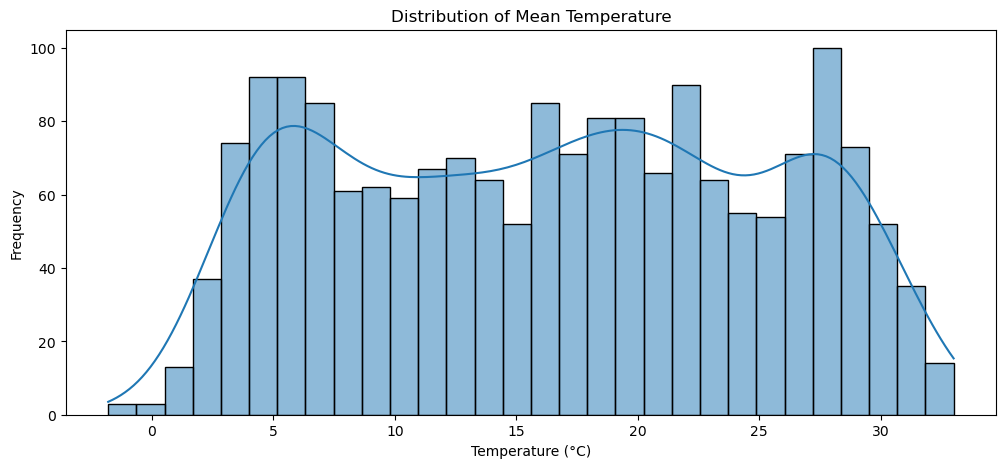

In [8]:

# CELL 4C: Temperature Distribution

plt.figure(figsize=(12, 5))

sns.histplot(
    weather_df["mean_temperature"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Mean Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

plt.show()


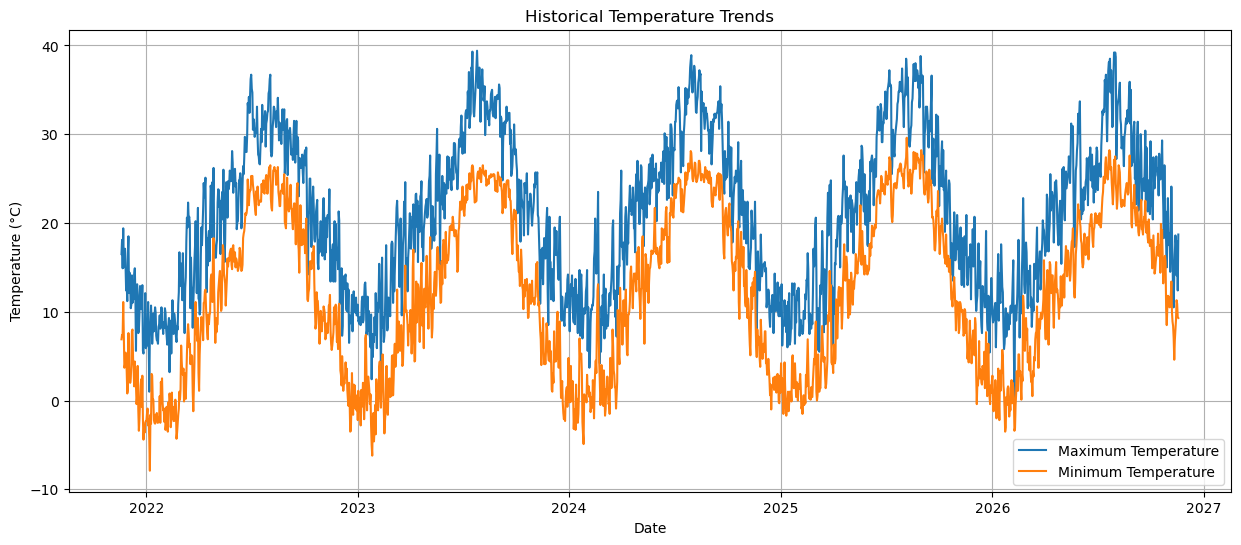

In [9]:

# CELL 4D: Daily Temperature Trend

plt.figure(figsize=(15, 6))

plt.plot(
    weather_df["date"],
    weather_df["max_temperature"],
    label="Maximum Temperature"
)

plt.plot(
    weather_df["date"],
    weather_df["min_temperature"],
    label="Minimum Temperature"
)

plt.title("Historical Temperature Trends")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)

plt.show()


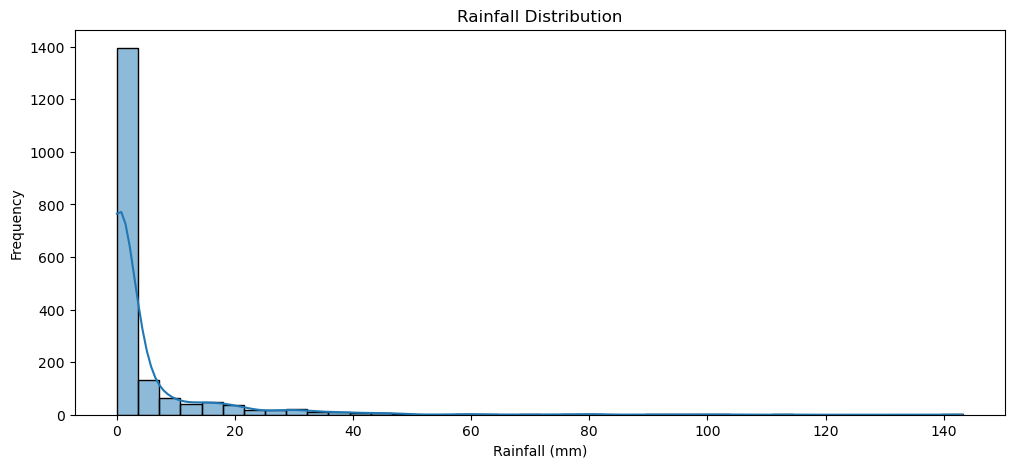

Total Rainfall: 8232.3 mm
Rainy Days: 962


In [10]:

# CELL 4E: Rainfall Distribution

plt.figure(figsize=(12, 5))

sns.histplot(
    weather_df["rainfall"].dropna(),
    bins=40,
    kde=True
)

plt.title("Rainfall Distribution")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

print("Total Rainfall:", weather_df["rainfall"].sum(), "mm")

print(
    "Rainy Days:",
    (weather_df["rainfall"] > 0).sum()
)


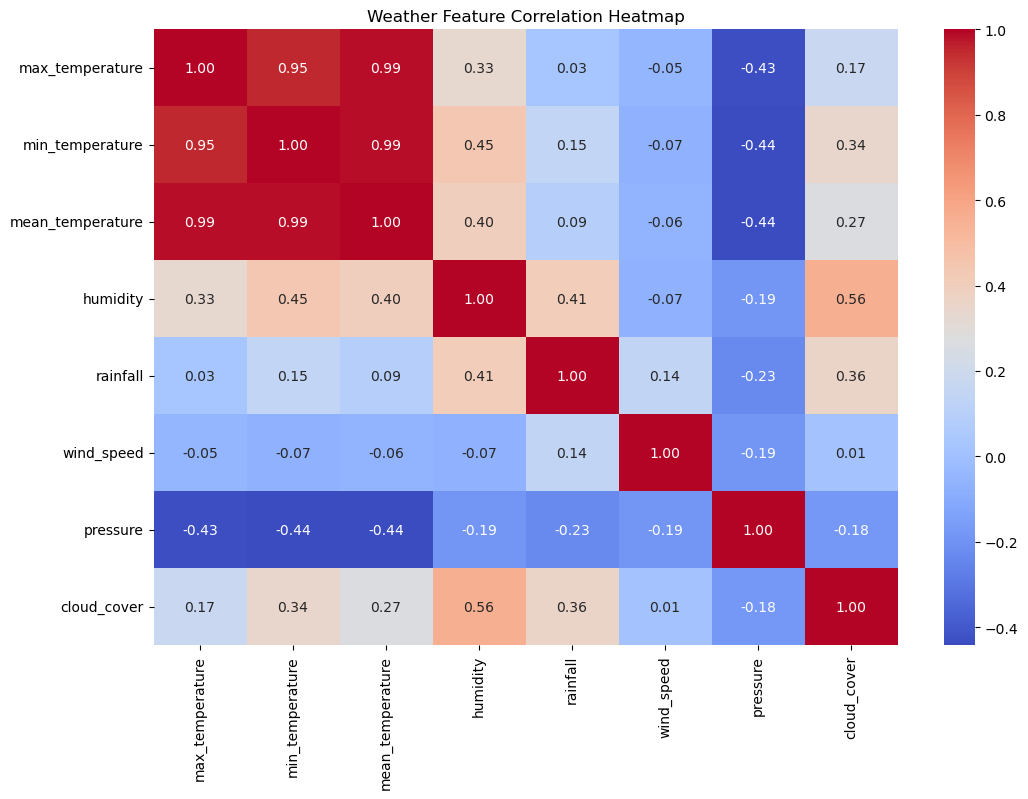

In [11]:

# CELL 4F: Correlation Heatmap

numeric_data = weather_df.select_dtypes(include=np.number)

correlation = numeric_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Weather Feature Correlation Heatmap")

plt.show()


In [12]:

# CELL 5A: Data Cleaning

# Create a copy of the original dataset
weather_clean = weather_df.copy()

# Convert date column
weather_clean["date"] = pd.to_datetime(weather_clean["date"])

# Sort records by date
weather_clean = weather_clean.sort_values("date")

# Remove duplicate dates
weather_clean = weather_clean.drop_duplicates(
    subset=["date"]
)

# Check missing values
print("Missing values before cleaning:")
display(weather_clean.isnull().sum())

# Fill missing numeric values using time interpolation
weather_clean = weather_clean.set_index("date")

weather_clean = weather_clean.interpolate(
    method="time",
    limit_area="inside"
)

weather_clean = weather_clean.reset_index()

print("\nMissing values after interpolation:")
display(weather_clean.isnull().sum())


Missing values before cleaning:


date                0
max_temperature     0
min_temperature     0
mean_temperature    0
humidity            0
rainfall            0
wind_speed          0
pressure            0
cloud_cover         0
dtype: int64


Missing values after interpolation:


date                0
max_temperature     0
min_temperature     0
mean_temperature    0
humidity            0
rainfall            0
wind_speed          0
pressure            0
cloud_cover         0
dtype: int64

In [13]:

# CELL 5B: Handle Remaining Missing Values

numeric_columns = weather_clean.select_dtypes(
    include=np.number
).columns

# Fill remaining missing values with median
for column in numeric_columns:
    weather_clean[column] = weather_clean[column].fillna(
        weather_clean[column].median()
    )

print("Remaining missing values:")
display(weather_clean.isnull().sum())

print("\nCleaned dataset shape:", weather_clean.shape)


Remaining missing values:


date                0
max_temperature     0
min_temperature     0
mean_temperature    0
humidity            0
rainfall            0
wind_speed          0
pressure            0
cloud_cover         0
dtype: int64


Cleaned dataset shape: (1826, 9)


In [14]:

# CELL 5C: Date Feature Engineering

weather_clean["year"] = weather_clean["date"].dt.year

weather_clean["month"] = weather_clean["date"].dt.month

weather_clean["day"] = weather_clean["date"].dt.day

weather_clean["day_of_week"] = weather_clean["date"].dt.dayofweek

weather_clean["day_of_year"] = weather_clean["date"].dt.dayofyear

# Create season feature
def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-Monsoon"


weather_clean["season"] = weather_clean["month"].apply(
    get_season
)

display(weather_clean.head())


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover,year,month,day,day_of_week,day_of_year,season
0,2021-11-19,16.5,6.9,11.0,79,0.0,13.9,1016.9,78,2021,11,19,4,323,Post-Monsoon
1,2021-11-20,18.1,7.4,11.8,75,0.0,17.3,1019.0,4,2021,11,20,5,324,Post-Monsoon
2,2021-11-21,14.9,7.4,11.4,84,4.1,14.3,1022.2,60,2021,11,21,6,325,Post-Monsoon
3,2021-11-22,19.4,11.1,14.1,90,27.5,47.0,1008.3,100,2021,11,22,0,326,Post-Monsoon
4,2021-11-23,15.0,7.4,11.7,62,0.5,34.8,1003.7,48,2021,11,23,1,327,Post-Monsoon


In [15]:

# CELL 5D: Lag Features

weather_features = [
    "mean_temperature",
    "humidity",
    "rainfall",
    "wind_speed"
]

for column in weather_features:

    weather_clean[f"{column}_lag_1"] = (
        weather_clean[column].shift(1)
    )

    weather_clean[f"{column}_lag_2"] = (
        weather_clean[column].shift(2)
    )

    weather_clean[f"{column}_lag_3"] = (
        weather_clean[column].shift(3)
    )

display(weather_clean.head(10))


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover,year,...,mean_temperature_lag_3,humidity_lag_1,humidity_lag_2,humidity_lag_3,rainfall_lag_1,rainfall_lag_2,rainfall_lag_3,wind_speed_lag_1,wind_speed_lag_2,wind_speed_lag_3
0,2021-11-19,16.5,6.9,11.0,79,0.0,13.9,1016.9,78,2021,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-11-20,18.1,7.4,11.8,75,0.0,17.3,1019.0,4,2021,...,NaN,79.0,NaN,NaN,0.0,NaN,NaN,13.9,NaN,NaN
2,2021-11-21,14.9,7.4,11.4,84,4.1,14.3,1022.2,60,2021,...,NaN,75.0,79.0,NaN,0.0,0.0,NaN,17.3,13.9,NaN
3,2021-11-22,19.4,11.1,14.1,90,27.5,47.0,1008.3,100,2021,...,11.0,84.0,75.0,79.0,4.1,0.0,0.0,14.3,17.3,13.9
4,2021-11-23,15.0,7.4,11.7,62,0.5,34.8,1003.7,48,2021,...,11.8,90.0,84.0,75.0,27.5,4.1,0.0,47.0,14.3,17.3
5,2021-11-24,15.9,3.7,9.0,65,0.0,21.9,1008.0,6,2021,...,11.4,62.0,90.0,84.0,0.5,27.5,4.1,34.8,47.0,14.3
6,2021-11-25,17.1,4.0,10.0,63,0.0,21.7,1011.1,2,2021,...,14.1,65.0,62.0,90.0,0.0,0.5,27.5,21.9,34.8,47.0
7,2021-11-26,15.2,5.4,9.8,71,0.0,20.5,1014.2,2,2021,...,11.7,63.0,65.0,62.0,0.0,0.0,0.5,21.7,21.9,34.8
8,2021-11-27,12.4,4.7,7.9,56,0.0,33.5,1021.4,6,2021,...,9.0,71.0,63.0,65.0,0.0,0.0,0.0,20.5,21.7,21.9
9,2021-11-28,13.1,3.3,7.2,60,0.0,32.1,1030.0,7,2021,...,10.0,56.0,71.0,63.0,0.0,0.0,0.0,33.5,20.5,21.7


In [16]:

# CELL 5E: Rolling Average Features

weather_clean["temperature_rolling_3"] = (
    weather_clean["mean_temperature"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

weather_clean["temperature_rolling_7"] = (
    weather_clean["mean_temperature"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

weather_clean["humidity_rolling_3"] = (
    weather_clean["humidity"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

display(weather_clean.head(10))


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover,year,...,humidity_lag_3,rainfall_lag_1,rainfall_lag_2,rainfall_lag_3,wind_speed_lag_1,wind_speed_lag_2,wind_speed_lag_3,temperature_rolling_3,temperature_rolling_7,humidity_rolling_3
0,2021-11-19,16.5,6.9,11.0,79,0.0,13.9,1016.9,78,2021,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-11-20,18.1,7.4,11.8,75,0.0,17.3,1019.0,4,2021,...,NaN,0.0,NaN,NaN,13.9,NaN,NaN,NaN,NaN,NaN
2,2021-11-21,14.9,7.4,11.4,84,4.1,14.3,1022.2,60,2021,...,NaN,0.0,0.0,NaN,17.3,13.9,NaN,NaN,NaN,NaN
3,2021-11-22,19.4,11.1,14.1,90,27.5,47.0,1008.3,100,2021,...,79.0,4.1,0.0,0.0,14.3,17.3,13.9,11.400000,NaN,79.333333
4,2021-11-23,15.0,7.4,11.7,62,0.5,34.8,1003.7,48,2021,...,75.0,27.5,4.1,0.0,47.0,14.3,17.3,12.433333,NaN,83.000000
5,2021-11-24,15.9,3.7,9.0,65,0.0,21.9,1008.0,6,2021,...,84.0,0.5,27.5,4.1,34.8,47.0,14.3,12.400000,NaN,78.666667
6,2021-11-25,17.1,4.0,10.0,63,0.0,21.7,1011.1,2,2021,...,90.0,0.0,0.5,27.5,21.9,34.8,47.0,11.600000,NaN,72.333333
7,2021-11-26,15.2,5.4,9.8,71,0.0,20.5,1014.2,2,2021,...,62.0,0.0,0.0,0.5,21.7,21.9,34.8,10.233333,11.285714,63.333333
8,2021-11-27,12.4,4.7,7.9,56,0.0,33.5,1021.4,6,2021,...,65.0,0.0,0.0,0.0,20.5,21.7,21.9,9.600000,11.114286,66.333333
9,2021-11-28,13.1,3.3,7.2,60,0.0,32.1,1030.0,7,2021,...,63.0,0.0,0.0,0.0,33.5,20.5,21.7,9.233333,10.557143,63.333333


In [17]:

# CELL 5F: Final Dataset Preparation

weather_ml = weather_clean.dropna().copy()

# Reset index
weather_ml = weather_ml.reset_index(drop=True)

print("Original dataset shape:", weather_df.shape)

print("Final ML dataset shape:", weather_ml.shape)

print("\nRemaining missing values:")
print(weather_ml.isnull().sum().sum())

# Save processed dataset
processed_file = (
    PROJECT_DIR / "data" / "processed" / "weather_processed.csv"
)

weather_ml.to_csv(processed_file, index=False)

print("\nProcessed dataset saved successfully!")
print(processed_file)

display(weather_ml.head())


Original dataset shape: (1826, 9)
Final ML dataset shape: (1819, 30)

Remaining missing values:
0

Processed dataset saved successfully!
C:\Users\LOKI\Weather Prediction by Area\data\processed\weather_processed.csv


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover,year,...,humidity_lag_3,rainfall_lag_1,rainfall_lag_2,rainfall_lag_3,wind_speed_lag_1,wind_speed_lag_2,wind_speed_lag_3,temperature_rolling_3,temperature_rolling_7,humidity_rolling_3
0,2021-11-26,15.2,5.4,9.8,71,0.0,20.5,1014.2,2,2021,...,62.0,0.0,0.0,0.5,21.7,21.9,34.8,10.233333,11.285714,63.333333
1,2021-11-27,12.4,4.7,7.9,56,0.0,33.5,1021.4,6,2021,...,65.0,0.0,0.0,0.0,20.5,21.7,21.9,9.600000,11.114286,66.333333
2,2021-11-28,13.1,3.3,7.2,60,0.0,32.1,1030.0,7,2021,...,63.0,0.0,0.0,0.0,33.5,20.5,21.7,9.233333,10.557143,63.333333
3,2021-11-29,11.2,0.8,5.6,76,0.0,13.1,1029.5,48,2021,...,71.0,0.0,0.0,0.0,32.1,33.5,20.5,8.300000,9.957143,62.333333
4,2021-11-30,16.6,1.2,9.3,78,1.5,28.8,1021.5,47,2021,...,56.0,0.0,0.0,0.0,13.1,32.1,33.5,6.900000,8.742857,64.000000


In [18]:

# CELL 6A: Create 7-Day Forecast Dataset

# Input features available at the forecast starting date
base_features = [
    "mean_temperature",
    "max_temperature",
    "min_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure",
    "cloud_cover",
    "mean_temperature_lag_1",
    "mean_temperature_lag_2",
    "mean_temperature_lag_3",
    "humidity_lag_1",
    "rainfall_lag_1",
    "wind_speed_lag_1",
    "temperature_rolling_3",
    "temperature_rolling_7",
    "humidity_rolling_3"
]

# Store supervised records
forecast_records = []

# Create records for horizons 1 to 7
for i in range(len(weather_ml) - 7):

    current_row = weather_ml.iloc[i]

    for horizon in range(1, 8):

        future_row = weather_ml.iloc[i + horizon]

        forecast_records.append({

            "origin_date": current_row["date"],

            "target_date": future_row["date"],

            "horizon": horizon,

            **{
                feature: current_row[feature]
                for feature in base_features
            },

            "forecast_month": future_row["date"].month,

            "forecast_day_of_year": future_row["date"].dayofyear,

            "forecast_day_of_week": future_row["date"].dayofweek,

            "target_temperature": future_row["mean_temperature"]
        })


# Convert records into DataFrame
forecast_df = pd.DataFrame(forecast_records)

print("7-Day Forecast Dataset Created!")

print("Dataset Shape:", forecast_df.shape)

display(forecast_df.head(10))


7-Day Forecast Dataset Created!
Dataset Shape: (12684, 24)


,origin_date,target_date,horizon,mean_temperature,max_temperature,min_temperature,humidity,rainfall,wind_speed,pressure,...,humidity_lag_1,rainfall_lag_1,wind_speed_lag_1,temperature_rolling_3,temperature_rolling_7,humidity_rolling_3,forecast_month,forecast_day_of_year,forecast_day_of_week,target_temperature
0,2021-11-26,2021-11-27,1,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,331,5,7.9
1,2021-11-26,2021-11-28,2,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,332,6,7.2
2,2021-11-26,2021-11-29,3,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,333,0,5.6
3,2021-11-26,2021-11-30,4,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,334,1,9.3
4,2021-11-26,2021-12-01,5,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,12,335,2,14.6
5,2021-11-26,2021-12-02,6,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,12,336,3,8.2
6,2021-11-26,2021-12-03,7,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,12,337,4,7.5
7,2021-11-27,2021-11-28,1,7.9,12.4,4.7,56,0.0,33.5,1021.4,...,71.0,0.0,20.5,9.600000,11.114286,66.333333,11,332,6,7.2
8,2021-11-27,2021-11-29,2,7.9,12.4,4.7,56,0.0,33.5,1021.4,...,71.0,0.0,20.5,9.600000,11.114286,66.333333,11,333,0,5.6
9,2021-11-27,2021-11-30,3,7.9,12.4,4.7,56,0.0,33.5,1021.4,...,71.0,0.0,20.5,9.600000,11.114286,66.333333,11,334,1,9.3


In [19]:

# CELL 6B: Feature Selection

feature_columns = (
    base_features
    + [
        "horizon",
        "forecast_month",
        "forecast_day_of_year",
        "forecast_day_of_week"
    ]
)

X = forecast_df[feature_columns]

y = forecast_df["target_temperature"]

print("Input Features (X):", X.shape)

print("Target Variable (y):", y.shape)

print("\nFeature Names:")
print(X.columns.tolist())

print("\nTarget Preview:")
display(y.head())


Input Features (X): (12684, 21)
Target Variable (y): (12684,)

Feature Names:
['mean_temperature', 'max_temperature', 'min_temperature', 'humidity', 'rainfall', 'wind_speed', 'pressure', 'cloud_cover', 'mean_temperature_lag_1', 'mean_temperature_lag_2', 'mean_temperature_lag_3', 'humidity_lag_1', 'rainfall_lag_1', 'wind_speed_lag_1', 'temperature_rolling_3', 'temperature_rolling_7', 'humidity_rolling_3', 'horizon', 'forecast_month', 'forecast_day_of_year', 'forecast_day_of_week']

Target Preview:


0     7.9
1     7.2
2     5.6
3     9.3
4    14.6
Name: target_temperature, dtype: float64

In [20]:

# CELL 6C: Dataset Validation

print("Missing values in X:", X.isnull().sum().sum())

print("Missing values in y:", y.isnull().sum())

print("\nForecast Horizon Distribution:")

display(forecast_df["horizon"].value_counts().sort_index())

print("\nTarget Temperature Statistics:")

display(y.describe())

print("\nFinal Dataset Preview:")

display(forecast_df.head())


Missing values in X: 0
Missing values in y: 0

Forecast Horizon Distribution:


horizon
1    1812
2    1812
3    1812
4    1812
5    1812
6    1812
7    1812
Name: count, dtype: int64


Target Temperature Statistics:


count    12684.000000
mean        16.465153
std          8.676113
min         -1.800000
25%          8.600000
50%         16.800000
75%         23.800000
max         33.000000
Name: target_temperature, dtype: float64


Final Dataset Preview:


,origin_date,target_date,horizon,mean_temperature,max_temperature,min_temperature,humidity,rainfall,wind_speed,pressure,...,humidity_lag_1,rainfall_lag_1,wind_speed_lag_1,temperature_rolling_3,temperature_rolling_7,humidity_rolling_3,forecast_month,forecast_day_of_year,forecast_day_of_week,target_temperature
0,2021-11-26,2021-11-27,1,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,331,5,7.9
1,2021-11-26,2021-11-28,2,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,332,6,7.2
2,2021-11-26,2021-11-29,3,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,333,0,5.6
3,2021-11-26,2021-11-30,4,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,11,334,1,9.3
4,2021-11-26,2021-12-01,5,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,63.0,0.0,21.7,10.233333,11.285714,63.333333,12,335,2,14.6


In [21]:

# CELL 7A: Chronological Train-Test Split

# Sort data by forecast origin date
forecast_df = forecast_df.sort_values(
    "origin_date"
).reset_index(drop=True)

# Identify unique forecast starting dates
unique_dates = np.sort(
    forecast_df["origin_date"].unique()
)

# Calculate 80% cutoff
split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

# Split into training and testing data
train_data = forecast_df[
    forecast_df["origin_date"] < split_date
].copy()

test_data = forecast_df[
    forecast_df["origin_date"] >= split_date
].copy()

# Separate input features and target
X_train = train_data[feature_columns]
y_train = train_data["target_temperature"]

X_test = test_data[feature_columns]
y_test = test_data["target_temperature"]

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining starts:", train_data["origin_date"].min())
print("Training ends:", train_data["origin_date"].max())

print("\nTesting starts:", test_data["origin_date"].min())
print("Testing ends:", test_data["origin_date"].max())


Training Shape: (10143, 21)
Testing Shape: (2541, 21)

Training starts: 2021-11-26 00:00:00
Training ends: 2025-11-13 00:00:00

Testing starts: 2025-11-14 00:00:00
Testing ends: 2026-11-11 00:00:00


In [22]:

# CELL 7B: Baseline Prediction

baseline_predictions = test_data[
    "mean_temperature"
].values

print("Baseline predictions generated!")
print("Actual values:", y_test.head().values)
print("Predicted values:", baseline_predictions[:5])


Baseline predictions generated!
Actual values: [ 9.  10.2  8.5 11.3 14.8]
Predicted values: [13.9 13.9 13.9 13.9 13.9]


In [23]:

# CELL 7C: Train Random Forest Model

from sklearn.ensemble import RandomForestRegressor

# Initialize model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")


Random Forest Model Training Completed!


In [24]:

# CELL 7D: Make Predictions

rf_predictions = rf_model.predict(X_test)

print("Predictions generated successfully!")

prediction_results = pd.DataFrame({
    "Actual Temperature": y_test.values,
    "Predicted Temperature": rf_predictions,
    "Baseline Temperature": baseline_predictions,
    "Forecast Horizon": test_data["horizon"].values
})

display(prediction_results.head(10))


Predictions generated successfully!


,Actual Temperature,Predicted Temperature,Baseline Temperature,Forecast Horizon
0,9.0,11.443711,13.9,6
1,10.2,11.438844,13.9,7
2,8.5,11.439715,13.9,5
3,11.3,11.435850,13.9,4
4,14.8,11.596441,13.9,3
5,12.1,11.595995,13.9,2
6,12.7,11.716676,13.9,1
7,10.2,11.420425,12.7,6
8,9.0,11.411935,12.7,5
9,8.5,11.451834,12.7,4


In [25]:

# CELL 7E: Model Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Baseline metrics
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Random Forest metrics
rf_mae = mean_absolute_error(
    y_test, rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(
    y_test, rf_predictions
)

# Comparison table
evaluation_results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse],
    "R2 Score": [baseline_r2, rf_r2]
})

display(evaluation_results.round(3))


,Model,MAE,RMSE,R2 Score
0,Baseline,2.587,3.306,0.829
1,Random Forest,2.373,2.989,0.860


In [26]:

# CELL 7F: Horizon-wise Model Evaluation

horizon_results = []

for horizon in range(1, 8):

    mask = test_data["horizon"].values == horizon

    actual = y_test.values[mask]
    predicted = rf_predictions[mask]

    horizon_results.append({
        "Horizon": f"Day {horizon}",
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    })

horizon_metrics = pd.DataFrame(horizon_results)

display(horizon_metrics.round(3))


,Horizon,MAE,RMSE
0,Day 1,2.016,2.510
1,Day 2,2.160,2.753
2,Day 3,2.357,2.972
3,Day 4,2.512,3.099
4,Day 5,2.524,3.170
5,Day 6,2.508,3.168
6,Day 7,2.531,3.185


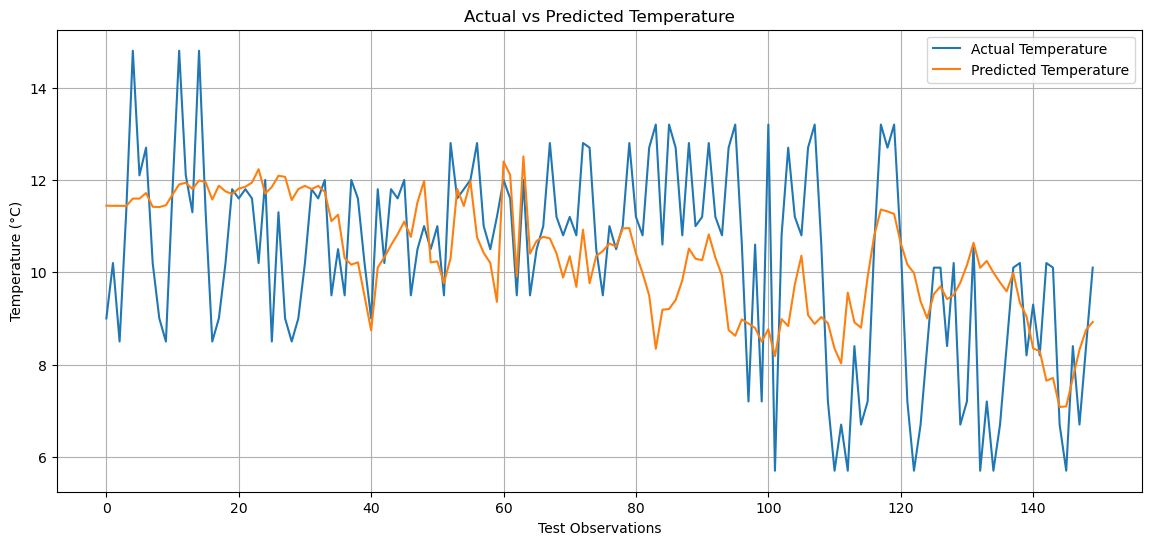

In [27]:

# CELL 7G: Actual vs Predicted Visualization

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.values[:150],
    label="Actual Temperature"
)

plt.plot(
    rf_predictions[:150],
    label="Predicted Temperature"
)

plt.title("Actual vs Predicted Temperature")
plt.xlabel("Test Observations")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)

plt.show()


In [28]:

# CELL 8A: Leakage-Free Train-Test Split

# Ensure dates are in datetime format
forecast_df["origin_date"] = pd.to_datetime(
    forecast_df["origin_date"]
)

forecast_df["target_date"] = pd.to_datetime(
    forecast_df["target_date"]
)

# Get unique forecast starting dates
unique_dates = np.sort(
    forecast_df["origin_date"].unique()
)

# Find 80% cutoff
split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

# Training data: target date must be before test period
train_data = forecast_df[
    forecast_df["target_date"] < split_date
].copy()

# Testing data: forecast origin starts from test period
test_data = forecast_df[
    forecast_df["origin_date"] >= split_date
].copy()

# Separate features and target
X_train = train_data[feature_columns]
y_train = train_data["target_temperature"]

X_test = test_data[feature_columns]
y_test = test_data["target_temperature"]

print("Leakage-free split completed!")

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("Training target ends:", train_data["target_date"].max())
print("Testing starts:", test_data["origin_date"].min())


Leakage-free split completed!
Training records: 10115
Testing records: 2541
Training target ends: 2025-11-13 00:00:00
Testing starts: 2025-11-14 00:00:00


In [29]:

# CELL 8B: Retrain Random Forest

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Improved Random Forest training completed!")


Improved Random Forest training completed!


In [30]:

# CELL 8C: Model Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

rf_predictions = rf_model.predict(X_test)

baseline_predictions = test_data[
    "mean_temperature"
].values

results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],

    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],

    "R2 Score": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

display(results.round(3))


,Model,MAE,RMSE,R2 Score
0,Baseline,2.587,3.306,0.829
1,Random Forest,2.368,2.985,0.861


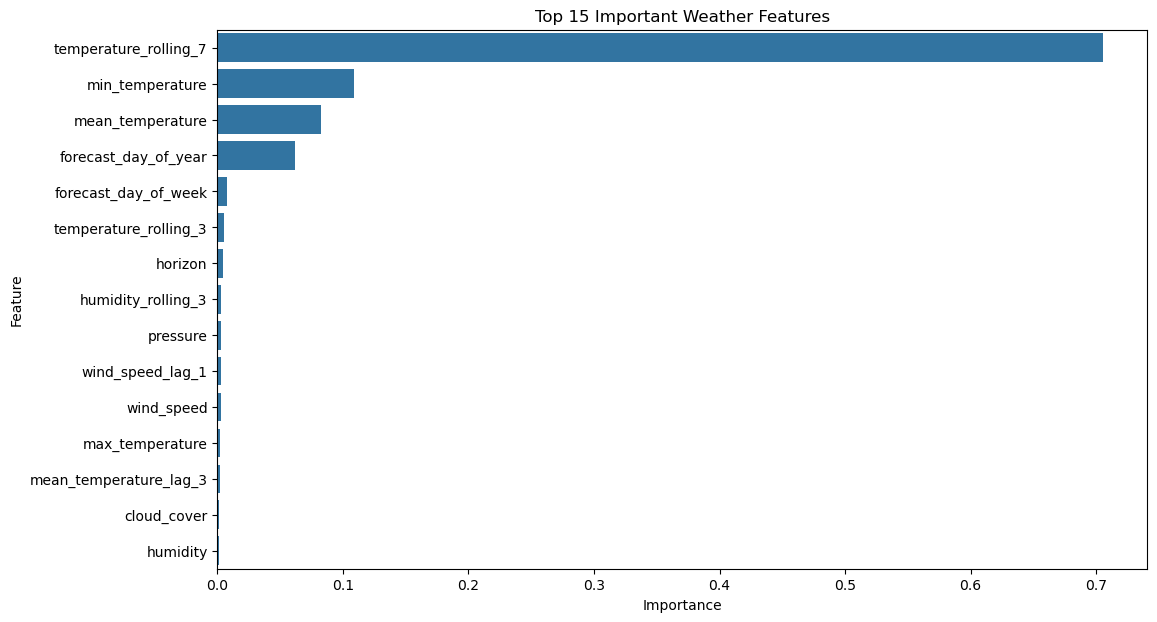

,Feature,Importance
15,temperature_rolling_7,0.705606
2,min_temperature,0.108776
0,mean_temperature,0.082301
19,forecast_day_of_year,0.061844
20,forecast_day_of_week,0.007937
14,temperature_rolling_3,0.005011
17,horizon,0.004816
16,humidity_rolling_3,0.003196
6,pressure,0.003014
13,wind_speed_lag_1,0.002649


In [31]:

# CELL 8D: Feature Importance

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Weather Features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

display(feature_importance.head(15))


In [32]:

# CELL 8E: Save Trained Model

import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save model
joblib.dump(
    rf_model,
    MODEL_DIR / "weather_random_forest.pkl"
)

# Save feature names
joblib.dump(
    feature_columns,
    MODEL_DIR / "feature_columns.pkl"
)

# Save evaluation results
results.to_csv(
    PROJECT_DIR / "data" / "processed" / "model_evaluation.csv",
    index=False
)

print("Model saved successfully!")

print("Model path:")
print(MODEL_DIR / "weather_random_forest.pkl")


Model saved successfully!
Model path:
C:\Users\LOKI\Weather Prediction by Area\models\weather_random_forest.pkl


In [33]:

# CELL 9A: Load Trained Model

import joblib

MODEL_DIR = PROJECT_DIR / "models"

loaded_model = joblib.load(
    MODEL_DIR / "weather_random_forest.pkl"
)

loaded_features = joblib.load(
    MODEL_DIR / "feature_columns.pkl"
)

print("Model loaded successfully!")
print("Total input features:", len(loaded_features))


Model loaded successfully!
Total input features: 21


In [34]:

# CELL 9B: Seven-Day Temperature Prediction

def predict_next_7_days(weather_data, model):

    # Get the latest historical observation
    latest = weather_data.sort_values("date").iloc[-1]

    # Store predictions
    future_predictions = []

    # Generate next seven days
    for horizon in range(1, 8):

        forecast_date = (
            latest["date"] + pd.Timedelta(days=horizon)
        )

        # Prepare input features
        input_data = {
            "mean_temperature": latest["mean_temperature"],
            "max_temperature": latest["max_temperature"],
            "min_temperature": latest["min_temperature"],
            "humidity": latest["humidity"],
            "rainfall": latest["rainfall"],
            "wind_speed": latest["wind_speed"],
            "pressure": latest["pressure"],
            "cloud_cover": latest["cloud_cover"],

            "mean_temperature_lag_1":
                latest["mean_temperature_lag_1"],

            "mean_temperature_lag_2":
                latest["mean_temperature_lag_2"],

            "mean_temperature_lag_3":
                latest["mean_temperature_lag_3"],

            "humidity_lag_1":
                latest["humidity_lag_1"],

            "rainfall_lag_1":
                latest["rainfall_lag_1"],

            "wind_speed_lag_1":
                latest["wind_speed_lag_1"],

            "temperature_rolling_3":
                latest["temperature_rolling_3"],

            "temperature_rolling_7":
                latest["temperature_rolling_7"],

            "humidity_rolling_3":
                latest["humidity_rolling_3"],

            "horizon": horizon,
            "forecast_month": forecast_date.month,
            "forecast_day_of_year": forecast_date.dayofyear,
            "forecast_day_of_week": forecast_date.dayofweek
        }

        # Arrange features in training order
        input_df = pd.DataFrame(
            [input_data]
        )[loaded_features]

        # Predict temperature
        predicted_temperature = model.predict(
            input_df
        )[0]

        future_predictions.append({
            "date": forecast_date,
            "day_ahead": horizon,
            "predicted_temperature": round(
                float(predicted_temperature), 2
            )
        })

    return pd.DataFrame(future_predictions)


In [35]:

# CELL 9C: Generate Weather Predictions

weather_forecast = predict_next_7_days(
    weather_clean,
    loaded_model
)

print("Seven-Day Temperature Forecast:")

display(weather_forecast)


Seven-Day Temperature Forecast:


,date,day_ahead,predicted_temperature
0,2026-11-19,1,12.62
1,2026-11-20,2,12.09
2,2026-11-21,3,11.73
3,2026-11-22,4,12.19
4,2026-11-23,5,11.88
5,2026-11-24,6,12.45
6,2026-11-25,7,11.76


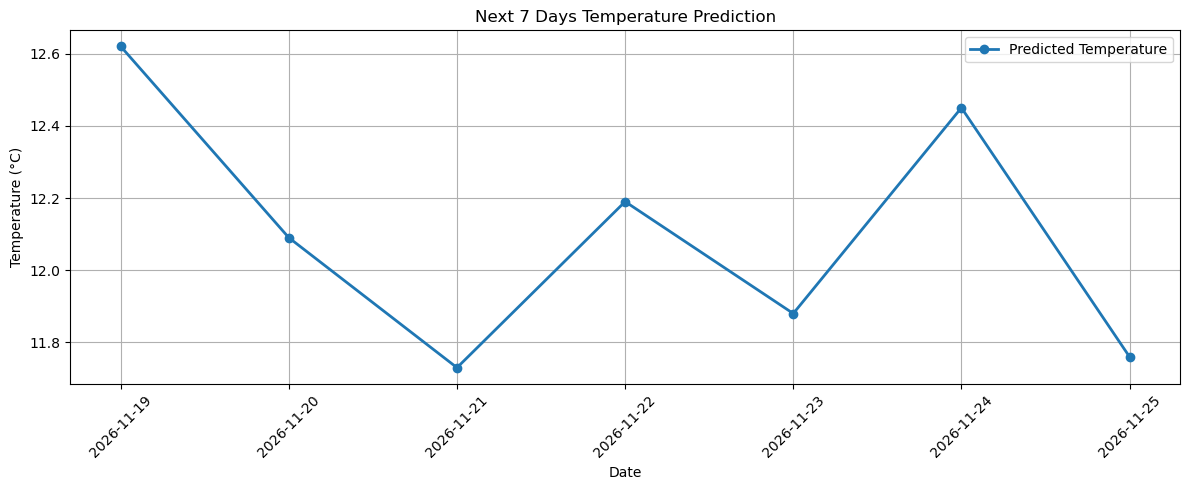

In [36]:

# CELL 9D: Forecast Visualization

plt.figure(figsize=(12, 5))

plt.plot(
    weather_forecast["date"],
    weather_forecast["predicted_temperature"],
    marker="o",
    linewidth=2,
    label="Predicted Temperature"
)

plt.title("Next 7 Days Temperature Prediction")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


In [37]:

# CELL 9E: Save Forecast

forecast_path = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "seven_day_temperature_forecast.csv"
)

weather_forecast.to_csv(
    forecast_path,
    index=False
)

print("Forecast saved successfully!")
print(forecast_path)


Forecast saved successfully!
C:\Users\LOKI\Weather Prediction by Area\data\processed\seven_day_temperature_forecast.csv


In [38]:

# CELL 10A: Fetch Open-Meteo 7-Day Forecast

forecast_url = "https://api.open-meteo.com/v1/forecast"

forecast_params = {
    "latitude": latitude,
    "longitude": longitude,
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "precipitation_sum",
        "wind_speed_10m_max"
    ],
    "forecast_days": 7,
    "timezone": "auto"
}

# Send API request
response = requests.get(
    forecast_url,
    params=forecast_params,
    timeout=30
)

response.raise_for_status()

api_forecast_data = response.json()

# Convert API data into DataFrame
api_forecast_df = pd.DataFrame(
    api_forecast_data["daily"]
)

# Rename columns
api_forecast_df.rename(columns={
    "time": "date",
    "temperature_2m_mean": "api_mean_temperature",
    "temperature_2m_max": "api_max_temperature",
    "temperature_2m_min": "api_min_temperature",
    "precipitation_sum": "api_rainfall",
    "wind_speed_10m_max": "api_wind_speed"
}, inplace=True)

api_forecast_df["date"] = pd.to_datetime(
    api_forecast_df["date"]
)

print("Open-Meteo forecast downloaded successfully!")

print("Location:", city)

display(api_forecast_df)


Open-Meteo forecast downloaded successfully!
Location: Tokyo


,date,api_mean_temperature,api_max_temperature,api_min_temperature,api_rainfall,api_wind_speed
0,2026-11-24,12.3,17.6,6.7,5.9,13.0
1,2026-11-25,9.6,12.8,6.5,0.0,9.6
2,2026-11-26,9.0,14.3,4.1,0.0,4.1
3,2026-11-27,10.3,16.3,6.2,0.0,5.6
4,2026-11-28,10.2,14.0,7.5,14.2,14.7
5,2026-11-29,9.0,12.5,4.9,0.0,17.5
6,2026-11-30,7.6,14.3,2.7,0.0,7.8


In [39]:

# CELL 11A: Merge ML and Open-Meteo Forecasts

# Ensure date columns have the same format
weather_forecast["date"] = pd.to_datetime(
    weather_forecast["date"]
)

api_forecast_df["date"] = pd.to_datetime(
    api_forecast_df["date"]
)

# Merge using common dates
comparison_df = pd.merge(
    weather_forecast,
    api_forecast_df,
    on="date",
    how="inner"
)

print("Forecast comparison completed!")

print("ML forecast records:", len(weather_forecast))
print("API forecast records:", len(api_forecast_df))
print("Common forecast dates:", len(comparison_df))

display(comparison_df)


Forecast comparison completed!
ML forecast records: 7
API forecast records: 7
Common forecast dates: 2


,date,day_ahead,predicted_temperature,api_mean_temperature,api_max_temperature,api_min_temperature,api_rainfall,api_wind_speed
0,2026-11-24,6,12.45,12.3,17.6,6.7,5.9,13.0
1,2026-11-25,7,11.76,9.6,12.8,6.5,0.0,9.6


In [40]:

# CELL 11B: Calculate Forecast Differences

if not comparison_df.empty:

    comparison_df["temperature_difference"] = (
        comparison_df["predicted_temperature"]
        - comparison_df["api_mean_temperature"]
    )

    comparison_df["absolute_difference"] = (
        comparison_df["temperature_difference"].abs()
    )

    print("Temperature comparison:")
    display(
        comparison_df[
            [
                "date",
                "predicted_temperature",
                "api_mean_temperature",
                "temperature_difference",
                "absolute_difference"
            ]
        ]
    )

    print(
        "\nAverage absolute difference:",
        round(comparison_df["absolute_difference"].mean(), 2),
        "°C"
    )

else:
    print("No overlapping forecast dates.")
    print("We cannot calculate a comparison yet.")


Temperature comparison:


,date,predicted_temperature,api_mean_temperature,temperature_difference,absolute_difference
0,2026-11-24,12.45,12.3,0.15,0.15
1,2026-11-25,11.76,9.6,2.16,2.16



Average absolute difference: 1.15 °C


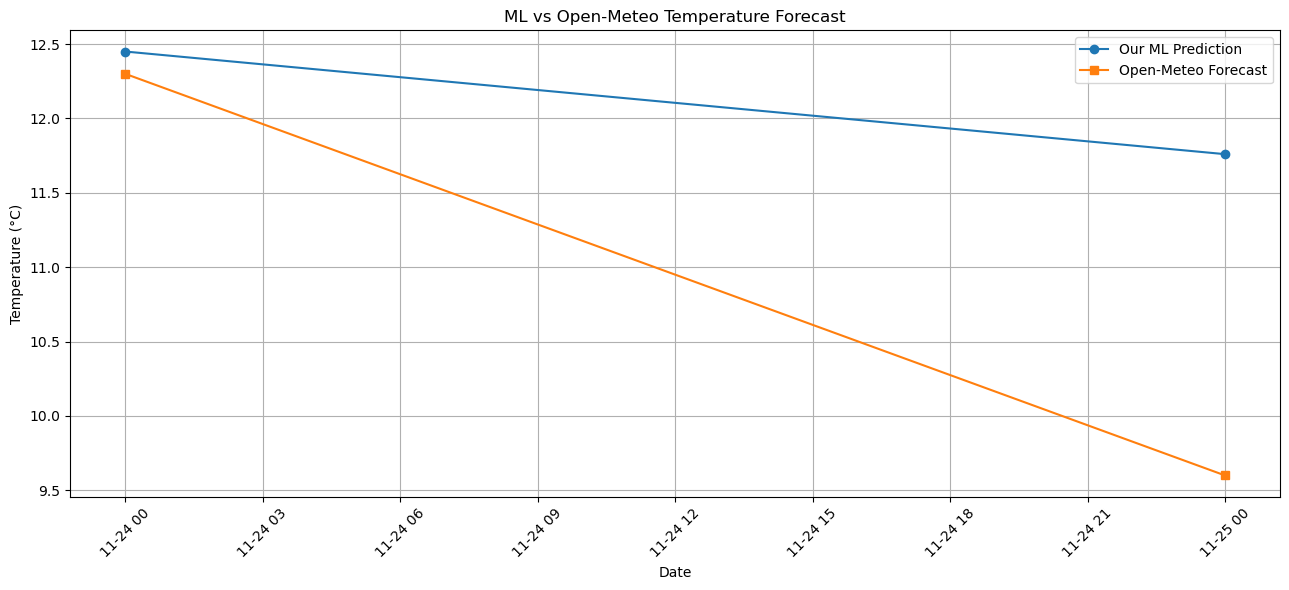

In [41]:

# CELL 11C: Compare Temperature Forecasts

if not comparison_df.empty:

    plt.figure(figsize=(13, 6))

    plt.plot(
        comparison_df["date"],
        comparison_df["predicted_temperature"],
        marker="o",
        label="Our ML Prediction"
    )

    plt.plot(
        comparison_df["date"],
        comparison_df["api_mean_temperature"],
        marker="s",
        label="Open-Meteo Forecast"
    )

    plt.title("ML vs Open-Meteo Temperature Forecast")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")

    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()

else:
    print("Visualization unavailable: no common dates.")


In [42]:

# CELL 11D: Save Comparison Results

if not comparison_df.empty:

    comparison_path = (
        PROJECT_DIR
        / "data"
        / "processed"
        / "forecast_comparison.csv"
    )

    comparison_df.to_csv(
        comparison_path,
        index=False
    )

    print("Comparison saved successfully!")
    print(comparison_path)

else:
    print("No comparison file saved because there are no common dates.")


Comparison saved successfully!
C:\Users\LOKI\Weather Prediction by Area\data\processed\forecast_comparison.csv


In [43]:

# CELL 12A: Create Multi-Variable Forecast Dataset

# Features available on the forecast starting date
base_features = [
    "mean_temperature",
    "max_temperature",
    "min_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure",
    "cloud_cover",
    "mean_temperature_lag_1",
    "mean_temperature_lag_2",
    "mean_temperature_lag_3",
    "humidity_lag_1",
    "rainfall_lag_1",
    "wind_speed_lag_1",
    "temperature_rolling_3",
    "temperature_rolling_7",
    "humidity_rolling_3"
]

# Future variables to predict
target_columns = [
    "mean_temperature",
    "humidity",
    "rainfall",
    "wind_speed"
]

# Store training records
multi_forecast_records = []

# Create seven-day supervised records
for i in range(len(weather_ml) - 7):

    current_row = weather_ml.iloc[i]

    for horizon in range(1, 8):

        future_row = weather_ml.iloc[i + horizon]

        record = {
            "origin_date": current_row["date"],
            "target_date": future_row["date"],
            "horizon": horizon
        }

        # Add historical input features
        for feature in base_features:
            record[feature] = current_row[feature]

        # Add future calendar features
        record["forecast_month"] = future_row["date"].month
        record["forecast_day_of_year"] = (
            future_row["date"].dayofyear
        )
        record["forecast_day_of_week"] = (
            future_row["date"].dayofweek
        )

        # Add future target variables
        for target in target_columns:
            record[f"target_{target}"] = future_row[target]

        multi_forecast_records.append(record)


# Convert to DataFrame
multi_forecast_df = pd.DataFrame(
    multi_forecast_records
)

print("Multi-variable dataset created!")
print("Dataset shape:", multi_forecast_df.shape)

display(multi_forecast_df.head(10))


Multi-variable dataset created!
Dataset shape: (12684, 27)


,origin_date,target_date,horizon,mean_temperature,max_temperature,min_temperature,humidity,rainfall,wind_speed,pressure,...,temperature_rolling_3,temperature_rolling_7,humidity_rolling_3,forecast_month,forecast_day_of_year,forecast_day_of_week,target_mean_temperature,target_humidity,target_rainfall,target_wind_speed
0,2021-11-26,2021-11-27,1,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,10.233333,11.285714,63.333333,11,331,5,7.9,56,0.0,33.5
1,2021-11-26,2021-11-28,2,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,10.233333,11.285714,63.333333,11,332,6,7.2,60,0.0,32.1
2,2021-11-26,2021-11-29,3,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,10.233333,11.285714,63.333333,11,333,0,5.6,76,0.0,13.1
3,2021-11-26,2021-11-30,4,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,10.233333,11.285714,63.333333,11,334,1,9.3,78,1.5,28.8
4,2021-11-26,2021-12-01,5,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,10.233333,11.285714,63.333333,12,335,2,14.6,74,42.4,61.0
5,2021-11-26,2021-12-02,6,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,10.233333,11.285714,63.333333,12,336,3,8.2,58,0.3,36.7
6,2021-11-26,2021-12-03,7,9.8,15.2,5.4,71,0.0,20.5,1014.2,...,10.233333,11.285714,63.333333,12,337,4,7.5,76,0.0,20.8
7,2021-11-27,2021-11-28,1,7.9,12.4,4.7,56,0.0,33.5,1021.4,...,9.600000,11.114286,66.333333,11,332,6,7.2,60,0.0,32.1
8,2021-11-27,2021-11-29,2,7.9,12.4,4.7,56,0.0,33.5,1021.4,...,9.600000,11.114286,66.333333,11,333,0,5.6,76,0.0,13.1
9,2021-11-27,2021-11-30,3,7.9,12.4,4.7,56,0.0,33.5,1021.4,...,9.600000,11.114286,66.333333,11,334,1,9.3,78,1.5,28.8


In [44]:

# CELL 13A: Prepare Multi-Variable Training Data

# Convert date columns
multi_forecast_df["origin_date"] = pd.to_datetime(
    multi_forecast_df["origin_date"]
)

multi_forecast_df["target_date"] = pd.to_datetime(
    multi_forecast_df["target_date"]
)

# Sort dates
multi_forecast_df = multi_forecast_df.sort_values(
    "origin_date"
).reset_index(drop=True)

# Find chronological cutoff
unique_dates = np.sort(
    multi_forecast_df["origin_date"].unique()
)

split_index = int(len(unique_dates) * 0.80)
split_date = unique_dates[split_index]

# Leakage-free training records
train_multi = multi_forecast_df[
    multi_forecast_df["target_date"] < split_date
].copy()

# Testing records
test_multi = multi_forecast_df[
    multi_forecast_df["origin_date"] >= split_date
].copy()

# Select input features
multi_feature_columns = (
    base_features
    + [
        "horizon",
        "forecast_month",
        "forecast_day_of_year",
        "forecast_day_of_week"
    ]
)

X_train_multi = train_multi[multi_feature_columns]
X_test_multi = test_multi[multi_feature_columns]

print("Training shape:", X_train_multi.shape)
print("Testing shape:", X_test_multi.shape)

print("Training ends:", train_multi["target_date"].max())
print("Testing starts:", test_multi["origin_date"].min())


Training shape: (10115, 21)
Testing shape: (2541, 21)
Training ends: 2025-11-13 00:00:00
Testing starts: 2025-11-14 00:00:00


In [45]:

# CELL 13B: Train Four Weather Prediction Models

from sklearn.ensemble import RandomForestRegressor

# Store trained models
weather_models = {}

# Store model predictions
weather_predictions = {}

# Define model parameters
model_parameters = {
    "n_estimators": 200,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "random_state": 42,
    "n_jobs": -1
}

# Train separate models
for target in target_columns:

    target_name = f"target_{target}"

    y_train_multi = train_multi[target_name]
    y_test_multi = test_multi[target_name]

    # Initialize model
    model = RandomForestRegressor(
        **model_parameters
    )

    # Train model
    model.fit(
        X_train_multi,
        y_train_multi
    )

    # Generate predictions
    predictions = model.predict(
        X_test_multi
    )

    # Store results
    weather_models[target] = model
    weather_predictions[target] = predictions

    print(f"{target} model trained successfully!")

print("\nAll four models trained successfully!")


mean_temperature model trained successfully!
humidity model trained successfully!
rainfall model trained successfully!
wind_speed model trained successfully!

All four models trained successfully!


In [46]:

# CELL 13C: Evaluate Multi-Variable Models

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

evaluation_records = []

for target in target_columns:

    actual = test_multi[f"target_{target}"].values

    predicted = weather_predictions[target]

    mae = mean_absolute_error(
        actual, predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(
        actual, predicted
    )

    evaluation_records.append({
        "Weather Variable": target,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create evaluation DataFrame
multi_model_results = pd.DataFrame(
    evaluation_records
)

display(multi_model_results.round(3))


,Weather Variable,MAE,RMSE,R2 Score
0,mean_temperature,2.371,2.987,0.860
1,humidity,11.086,14.046,0.206
2,rainfall,7.388,14.501,0.010
3,wind_speed,5.142,6.586,-0.862


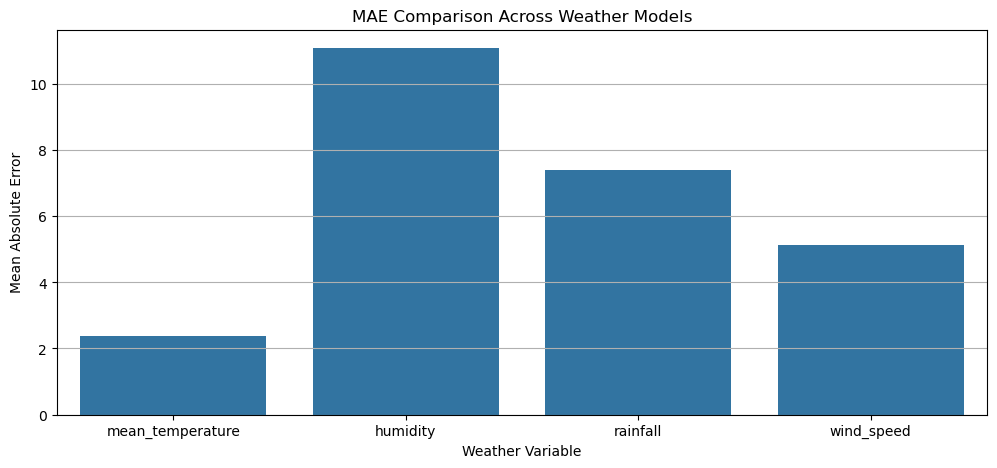

In [47]:

# CELL 13D: Model Performance Visualization

plt.figure(figsize=(12, 5))

sns.barplot(
    data=multi_model_results,
    x="Weather Variable",
    y="MAE"
)

plt.title("MAE Comparison Across Weather Models")
plt.xlabel("Weather Variable")
plt.ylabel("Mean Absolute Error")

plt.grid(axis="y")
plt.show()


In [48]:

# CELL 13E: Save Multi-Variable Models

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save individual models
for target, model in weather_models.items():

    model_path = (
        MODEL_DIR / f"{target}_random_forest.pkl"
    )

    joblib.dump(model, model_path)

    print(f"Saved: {model_path.name}")

# Save feature configuration
joblib.dump(
    multi_feature_columns,
    MODEL_DIR / "multi_feature_columns.pkl"
)

# Save evaluation results
evaluation_path = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "multi_model_evaluation.csv"
)

multi_model_results.to_csv(
    evaluation_path,
    index=False
)

print("\nAll models and evaluation results saved!")


Saved: mean_temperature_random_forest.pkl
Saved: humidity_random_forest.pkl
Saved: rainfall_random_forest.pkl
Saved: wind_speed_random_forest.pkl

All models and evaluation results saved!


In [49]:

# CELL 14A: Recursive 7-Day Weather Prediction

def predict_7_day_weather(weather_data, models, feature_columns):

    # Get latest historical observation
    history = weather_data.sort_values("date").copy()
    latest = history.iloc[-1]

    # Current weather state
    state = {
        "mean_temperature": float(latest["mean_temperature"]),
        "max_temperature": float(latest["max_temperature"]),
        "min_temperature": float(latest["min_temperature"]),
        "humidity": float(latest["humidity"]),
        "rainfall": float(latest["rainfall"]),
        "wind_speed": float(latest["wind_speed"]),
        "pressure": float(latest["pressure"]),
        "cloud_cover": float(latest["cloud_cover"])
    }

    # Previous observations for lag features
    temperature_history = history["mean_temperature"].tail(3).tolist()
    humidity_history = history["humidity"].tail(3).tolist()

    rainfall_history = history["rainfall"].tail(1).tolist()
    wind_history = history["wind_speed"].tail(1).tolist()

    predictions = []

    # Predict next seven days
    for horizon in range(1, 8):

        forecast_date = (
            latest["date"] + pd.Timedelta(days=horizon)
        )

        # Prepare input features
        input_data = {
            **state,

            "mean_temperature_lag_1": temperature_history[-1],
            "mean_temperature_lag_2": temperature_history[-2],
            "mean_temperature_lag_3": temperature_history[-3],

            "humidity_lag_1": humidity_history[-1],
            "rainfall_lag_1": rainfall_history[-1],
            "wind_speed_lag_1": wind_history[-1],

            "temperature_rolling_3": np.mean(
                temperature_history[-3:]
            ),

            "temperature_rolling_7": (
                history["mean_temperature"].tail(7).mean()
                if horizon == 1
                else np.mean(temperature_history[-7:])
            ),

            "humidity_rolling_3": np.mean(
                humidity_history[-3:]
            ),

            "horizon": horizon,
            "forecast_month": forecast_date.month,
            "forecast_day_of_year": forecast_date.dayofyear,
            "forecast_day_of_week": forecast_date.dayofweek
        }

        # Arrange features in training order
        input_df = pd.DataFrame(
            [input_data]
        )[feature_columns]

        # Predict four weather variables
        day_prediction = {}

        for variable, model in models.items():

            predicted_value = float(
                model.predict(input_df)[0]
            )

            day_prediction[variable] = predicted_value

        # Apply basic physical bounds
        day_prediction["mean_temperature"] = np.clip(
            day_prediction["mean_temperature"], -80, 60
        )

        day_prediction["humidity"] = np.clip(
            day_prediction["humidity"], 0, 100
        )

        day_prediction["rainfall"] = max(
            0, day_prediction["rainfall"]
        )

        day_prediction["wind_speed"] = max(
            0, day_prediction["wind_speed"]
        )

        # Store prediction
        predictions.append({
            "date": forecast_date,
            "day_ahead": horizon,
            "predicted_temperature": round(
                day_prediction["mean_temperature"], 2
            ),
            "predicted_humidity": round(
                day_prediction["humidity"], 2
            ),
            "predicted_rainfall": round(
                day_prediction["rainfall"], 2
            ),
            "predicted_wind_speed": round(
                day_prediction["wind_speed"], 2
            )
        })

        # Update histories with predicted values
        temperature_history.append(
            day_prediction["mean_temperature"]
        )

        humidity_history.append(
            day_prediction["humidity"]
        )

        rainfall_history.append(
            day_prediction["rainfall"]
        )

        wind_history.append(
            day_prediction["wind_speed"]
        )

        # Keep only required recent observations
        temperature_history = temperature_history[-7:]
        humidity_history = humidity_history[-3:]
        rainfall_history = rainfall_history[-1:]
        wind_history = wind_history[-1:]

        # Update current state for next day
        state["mean_temperature"] = (
            day_prediction["mean_temperature"]
        )

        state["humidity"] = day_prediction["humidity"]
        state["rainfall"] = day_prediction["rainfall"]
        state["wind_speed"] = day_prediction["wind_speed"]

    return pd.DataFrame(predictions)


In [50]:

# CELL 14B: Generate Multi-Variable Forecast

multi_weather_forecast = predict_7_day_weather(
    weather_data=weather_ml,
    models=weather_models,
    feature_columns=multi_feature_columns
)

print("7-Day Weather Prediction Generated!")

display(multi_weather_forecast)


7-Day Weather Prediction Generated!


,date,day_ahead,predicted_temperature,predicted_humidity,predicted_rainfall,predicted_wind_speed
0,2026-11-19,1,12.04,70.36,1.32,24.24
1,2026-11-20,2,10.74,73.01,2.60,23.53
2,2026-11-21,3,11.94,74.05,1.50,25.82
3,2026-11-22,4,11.65,73.74,1.46,26.43
4,2026-11-23,5,11.95,76.55,12.45,25.68
5,2026-11-24,6,12.38,76.14,6.33,28.40
6,2026-11-25,7,11.61,74.27,10.24,26.23


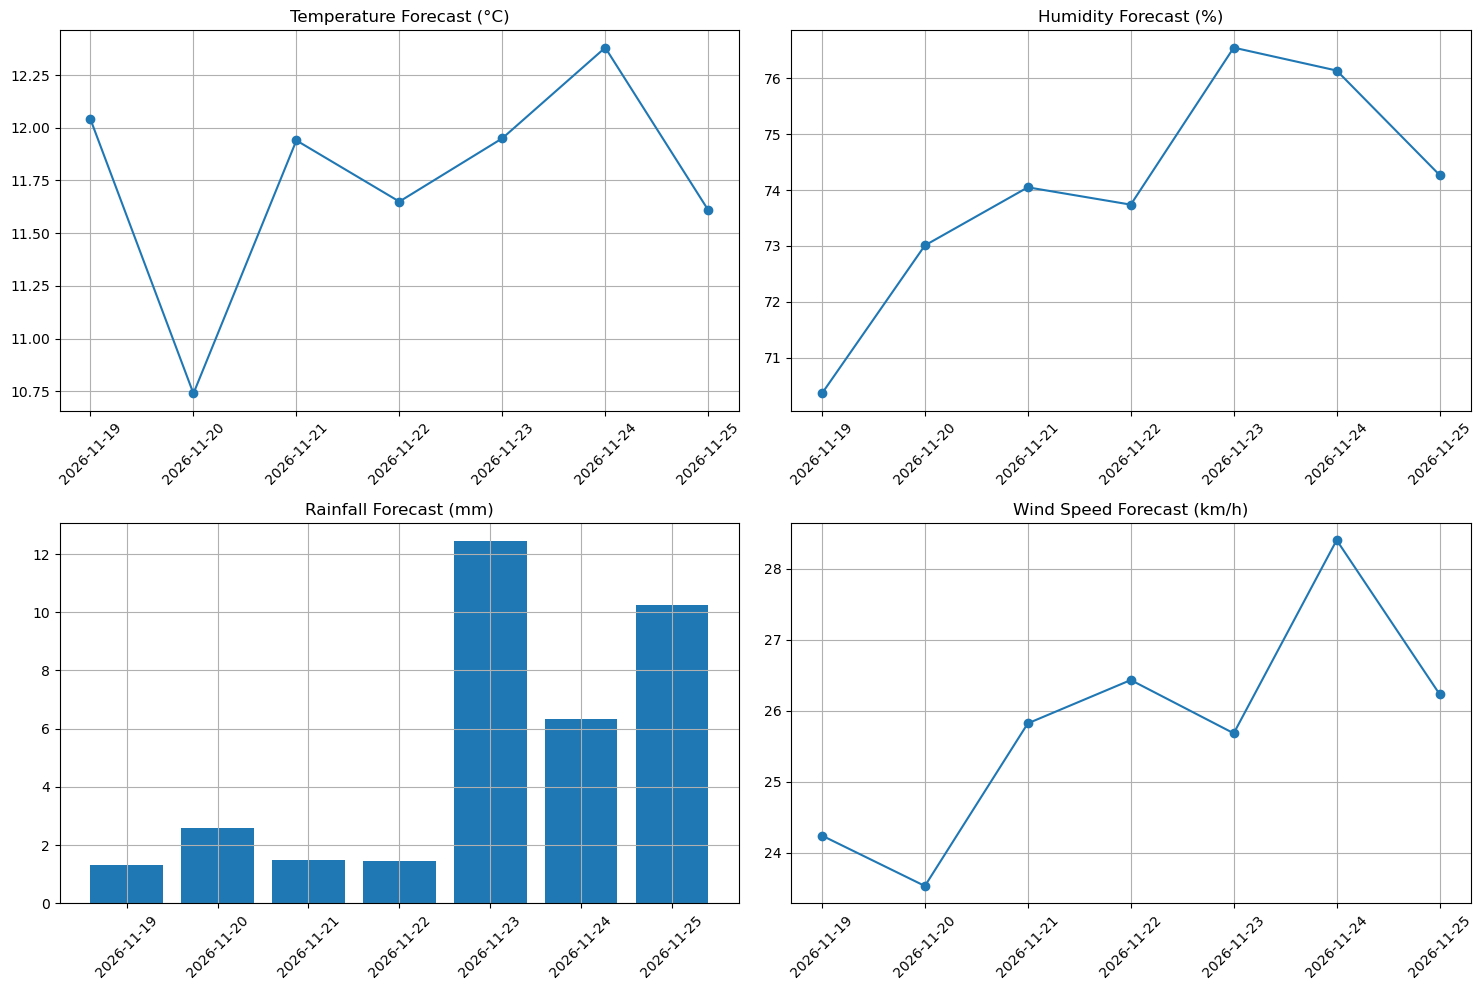

In [51]:

# CELL 14C: Weather Forecast Visualization

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Temperature
axes[0, 0].plot(
    multi_weather_forecast["date"],
    multi_weather_forecast["predicted_temperature"],
    marker="o"
)
axes[0, 0].set_title("Temperature Forecast (°C)")

# Humidity
axes[0, 1].plot(
    multi_weather_forecast["date"],
    multi_weather_forecast["predicted_humidity"],
    marker="o"
)
axes[0, 1].set_title("Humidity Forecast (%)")

# Rainfall
axes[1, 0].bar(
    multi_weather_forecast["date"],
    multi_weather_forecast["predicted_rainfall"]
)
axes[1, 0].set_title("Rainfall Forecast (mm)")

# Wind speed
axes[1, 1].plot(
    multi_weather_forecast["date"],
    multi_weather_forecast["predicted_wind_speed"],
    marker="o"
)
axes[1, 1].set_title("Wind Speed Forecast (km/h)")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()
plt.show()


In [52]:

# CELL 14D: Save Multi-Variable Forecast

forecast_file = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "multi_variable_7_day_forecast.csv"
)

multi_weather_forecast.to_csv(
    forecast_file,
    index=False
)

print("Forecast saved successfully!")
print("File:", forecast_file)


Forecast saved successfully!
File: C:\Users\LOKI\Weather Prediction by Area\data\processed\multi_variable_7_day_forecast.csv


In [53]:

# CELL 15A: Create Streamlit Application

app_code = r'''
import streamlit as st
import pandas as pd
import requests
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Weather Prediction by Area",
    page_icon="🌦️",
    layout="wide"
)

st.title("🌦️ Weather Prediction by Area")

st.write(
    "Explore seven-day weather forecasts for cities worldwide."
)

# Location search
city = st.text_input(
    "Enter City or Area",
    placeholder="Example: Hyderabad, London, Tokyo"
)

if st.button("Get Weather Forecast"):

    if not city.strip():
        st.warning("Please enter a city name.")

    else:
        try:
            # Geocoding API
            geo_url = (
                "https://geocoding-api.open-meteo.com/v1/search"
            )

            geo_params = {
                "name": city,
                "count": 5,
                "language": "en",
                "format": "json"
            }

            geo_response = requests.get(
                geo_url,
                params=geo_params,
                timeout=30
            )

            geo_response.raise_for_status()

            geo_data = geo_response.json()

            if not geo_data.get("results"):
                st.error("Location not found.")
                st.stop()

            locations = geo_data["results"]

            # Select matching location
            location_options = [
                f"{item['name']}, "
                f"{item.get('admin1', '')}, "
                f"{item.get('country', '')}"
                for item in locations
            ]

            selected = st.selectbox(
                "Select your location",
                range(len(locations)),
                format_func=lambda i: location_options[i]
            )

            location = locations[selected]

            latitude = location["latitude"]
            longitude = location["longitude"]

            st.subheader(
                f"Weather Forecast: {location['name']}"
            )

            st.caption(
                f"Latitude: {latitude} | "
                f"Longitude: {longitude} | "
                f"Country: {location.get('country', 'N/A')}"
            )

            # Weather forecast API
            weather_url = (
                "https://api.open-meteo.com/v1/forecast"
            )

            weather_params = {
                "latitude": latitude,
                "longitude": longitude,
                "daily": [
                    "temperature_2m_mean",
                    "temperature_2m_max",
                    "temperature_2m_min",
                    "precipitation_sum",
                    "wind_speed_10m_max"
                ],
                "hourly": [
                    "relative_humidity_2m"
                ],
                "forecast_days": 7,
                "timezone": "auto"
            }

            weather_response = requests.get(
                weather_url,
                params=weather_params,
                timeout=30
            )

            weather_response.raise_for_status()

            weather_data = weather_response.json()

            daily_df = pd.DataFrame(
                weather_data["daily"]
            )

            daily_df["time"] = pd.to_datetime(
                daily_df["time"]
            )

            hourly_df = pd.DataFrame(
                weather_data["hourly"]
            )

            humidity = (
                pd.Series(hourly_df["relative_humidity_2m"])
                .mean()
            )

            # Current dashboard metrics
            col1, col2, col3, col4 = st.columns(4)

            col1.metric(
                "Average Forecast Temperature",
                f"{daily_df['temperature_2m_mean'].mean():.1f} °C"
            )

            col2.metric(
                "Average Humidity",
                f"{humidity:.1f} %"
            )

            col3.metric(
                "Total Forecast Rainfall",
                f"{daily_df['precipitation_sum'].sum():.1f} mm"
            )

            col4.metric(
                "Maximum Wind Speed",
                f"{daily_df['wind_speed_10m_max'].max():.1f} km/h"
            )

            # Forecast table
            st.subheader("📅 Seven-Day Forecast")

            display_df = daily_df.rename(columns={
                "time": "Date",
                "temperature_2m_mean": "Mean Temperature (°C)",
                "temperature_2m_max": "Max Temperature (°C)",
                "temperature_2m_min": "Min Temperature (°C)",
                "precipitation_sum": "Rainfall (mm)",
                "wind_speed_10m_max": "Wind Speed (km/h)"
            })

            st.dataframe(
                display_df,
                use_container_width=True,
                hide_index=True
            )

            # Temperature chart
            st.subheader("🌡️ Temperature Forecast")

            chart_df = daily_df.set_index("time")[
                [
                    "temperature_2m_min",
                    "temperature_2m_mean",
                    "temperature_2m_max"
                ]
            ]

            chart_df.columns = [
                "Minimum",
                "Mean",
                "Maximum"
            ]

            st.line_chart(chart_df)

            # Rainfall chart
            st.subheader("🌧️ Rainfall Forecast")

            st.bar_chart(
                daily_df.set_index("time")[
                    "precipitation_sum"
                ]
            )

            st.success("Weather forecast retrieved successfully!")

            st.caption(
                "Forecast data provided by Open-Meteo. "
                "These are API forecasts, not predictions "
                "from our trained Random Forest models."
            )

        except requests.RequestException as error:
            st.error(f"Weather API error: {error}")

        except Exception as error:
            st.error(f"An unexpected error occurred: {error}")


st.divider()

st.caption(
    "Weather Prediction by Area | Python | Machine Learning | Streamlit"
)
'''

APP_DIR = PROJECT_DIR / "app"
APP_DIR.mkdir(parents=True, exist_ok=True)

app_file = APP_DIR / "app.py"

app_file.write_text(
    app_code,
    encoding="utf-8"
)

print("Streamlit application created successfully!")
print("Application path:", app_file)


Streamlit application created successfully!
Application path: C:\Users\LOKI\Weather Prediction by Area\app\app.py


In [54]:

# CELL 15B: Verify Application File

if app_file.exists():

    print("app.py exists!")

    print("File size:", app_file.stat().st_size, "bytes")

    print("\nApplication preview:")

    print(app_file.read_text(encoding="utf-8")[:500])

else:

    print("Application file not found!")


app.py exists!
File size: 6273 bytes

Application preview:

import streamlit as st
import pandas as pd
import requests
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Weather Prediction by Area",
    page_icon="🌦️",
    layout="wide"
)

st.title("🌦️ Weather Prediction by Area")

st.write(
    "Explore seven-day weather forecasts for cities worldwide."
)

# Location search
city = st.text_input(
    "Enter City or Area",
    placeholder="Example: Hyderabad, London, Tokyo"
)

if st.button("Get Weather Forecast"):

    if not city.strip


In [56]:

# CELL 16A: Check Saved Machine Learning Models

MODEL_DIR = PROJECT_DIR / "models"

required_files = [
    "mean_temperature_random_forest.pkl",
    "humidity_random_forest.pkl",
    "rainfall_random_forest.pkl",
    "wind_speed_random_forest.pkl",
    "multi_feature_columns.pkl"
]

for filename in required_files:

    file_path = MODEL_DIR / filename

    if file_path.exists():
        print("FOUND:", filename)
    else:
        print("MISSING:", filename)


FOUND: mean_temperature_random_forest.pkl
FOUND: humidity_random_forest.pkl
FOUND: rainfall_random_forest.pkl
FOUND: wind_speed_random_forest.pkl
FOUND: multi_feature_columns.pkl


In [1]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

evaluation_file = PROJECT_DIR / "data" / "processed" / "multi_model_evaluation.csv"

print("Evaluation file exists:", evaluation_file.exists())

if evaluation_file.exists():
    evaluation_df = pd.read_csv(evaluation_file)
    display(evaluation_df)

Evaluation file exists: True


,Weather Variable,MAE,RMSE,R2 Score
0,mean_temperature,2.370942,2.987151,0.860395
1,humidity,11.085865,14.045543,0.206269
2,rainfall,7.387539,14.500532,0.010292
3,wind_speed,5.141684,6.585517,-0.861810


In [2]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

data_path = PROJECT_DIR / "data" / "processed" / "weather_processed.csv"

weather_data = pd.read_csv(data_path)

variables = [
    "mean_temperature",
    "humidity",
    "rainfall",
    "wind_speed"
]

diagnostics = []

for col in variables:
    diagnostics.append({
        "Weather Variable": col,
        "Minimum": weather_data[col].min(),
        "Maximum": weather_data[col].max(),
        "Mean": weather_data[col].mean(),
        "Standard Deviation": weather_data[col].std(),
        "Missing Values": weather_data[col].isna().sum()
    })

diagnostics_df = pd.DataFrame(diagnostics)

display(diagnostics_df)

print(
    "Days with zero rainfall:",
    (weather_data["rainfall"] == 0).sum()
)

print(
    "Percentage of zero-rainfall days:",
    round((weather_data["rainfall"] == 0).mean() * 100, 2),
    "%"
)


,Weather Variable,Minimum,Maximum,Mean,Standard Deviation,Missing Values
0,mean_temperature,-1.8,33.0,16.442276,8.671221,0
1,humidity,25.0,96.0,71.106652,12.837250,0
2,rainfall,0.0,143.2,4.508081,11.276384,0
3,wind_speed,6.1,76.0,21.470533,10.465542,0


Days with zero rainfall: 860
Percentage of zero-rainfall days: 47.28 %


Total rainy days: 959
Average rainfall on rainy days: 8.55078206465068
Median rainfall on rainy days: 2.7
Maximum rainfall: 143.2


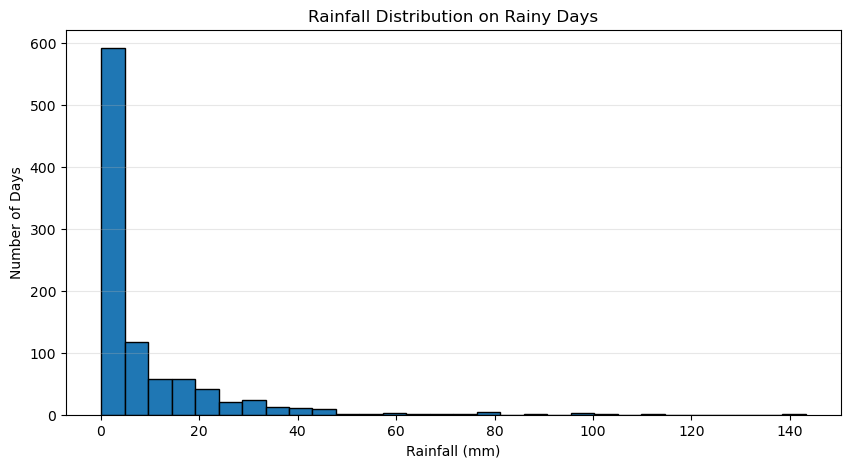

In [3]:
import matplotlib.pyplot as plt

# Rainfall on days when precipitation occurred
rainy_days = weather_data[
    weather_data["rainfall"] > 0
]["rainfall"]

print("Total rainy days:", len(rainy_days))
print("Average rainfall on rainy days:", rainy_days.mean())
print("Median rainfall on rainy days:", rainy_days.median())
print("Maximum rainfall:", rainy_days.max())

# Rainfall distribution
plt.figure(figsize=(10, 5))

plt.hist(rainy_days, bins=30, edgecolor="black")

plt.xlabel("Rainfall (mm)")
plt.ylabel("Number of Days")
plt.title("Rainfall Distribution on Rainy Days")

plt.grid(axis="y", alpha=0.3)
plt.show()


In [5]:
print("multi_forecast_df exists:", "multi_forecast_df" in globals())
print("weather_ml exists:", "weather_ml" in globals())
print("multi_feature_columns exists:", "multi_feature_columns" in globals())
print("PROJECT_DIR exists:", "PROJECT_DIR" in globals())

multi_forecast_df exists: False
weather_ml exists: False
multi_feature_columns exists: False
PROJECT_DIR exists: True


In [6]:

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Set project directory
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# 2. Load processed weather data
data_path = PROJECT_DIR / "data" / "processed" / "weather_processed.csv"

weather_ml = pd.read_csv(data_path)

weather_ml["date"] = pd.to_datetime(weather_ml["date"])
weather_ml = weather_ml.sort_values("date").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", weather_ml.shape)

# 3. Define input features
BASE_FEATURES = [
    "mean_temperature",
    "max_temperature",
    "min_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure",
    "cloud_cover",
    "mean_temperature_lag_1",
    "mean_temperature_lag_2",
    "mean_temperature_lag_3",
    "humidity_lag_1",
    "rainfall_lag_1",
    "wind_speed_lag_1",
    "temperature_rolling_3",
    "temperature_rolling_7",
    "humidity_rolling_3"
]

# 4. Define complete feature columns
multi_feature_columns = BASE_FEATURES + [
    "horizon",
    "forecast_month",
    "forecast_day_of_year",
    "forecast_day_of_week"
]

# 5. Rebuild multi-target training dataset
records = []

for i in range(len(weather_ml) - 7):

    current = weather_ml.iloc[i]

    for horizon in range(1, 8):

        future = weather_ml.iloc[i + horizon]

        row = {
            feature: current[feature]
            for feature in BASE_FEATURES
        }

        row["horizon"] = horizon
        row["forecast_month"] = future["month"]
        row["forecast_day_of_year"] = future["day_of_year"]
        row["forecast_day_of_week"] = future["day_of_week"]

        row["origin_date"] = current["date"]
        row["target_date"] = future["date"]

        for target in [
            "mean_temperature",
            "humidity",
            "rainfall",
            "wind_speed"
        ]:
            row[target + "_target"] = future[target]

        records.append(row)

multi_forecast_df = pd.DataFrame(records)

print("Multi-target dataset created!")
print("Dataset shape:", multi_forecast_df.shape)

display(multi_forecast_df.head())


Dataset loaded successfully!
Dataset shape: (1819, 30)
Multi-target dataset created!
Dataset shape: (12684, 27)


,mean_temperature,max_temperature,min_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover,mean_temperature_lag_1,mean_temperature_lag_2,...,horizon,forecast_month,forecast_day_of_year,forecast_day_of_week,origin_date,target_date,mean_temperature_target,humidity_target,rainfall_target,wind_speed_target
0,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,1,11,331,5,2021-11-26,2021-11-27,7.9,56,0.0,33.5
1,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,2,11,332,6,2021-11-26,2021-11-28,7.2,60,0.0,32.1
2,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,3,11,333,0,2021-11-26,2021-11-29,5.6,76,0.0,13.1
3,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,4,11,334,1,2021-11-26,2021-11-30,9.3,78,1.5,28.8
4,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,5,12,335,2,2021-11-26,2021-12-01,14.6,74,42.4,61.0


In [7]:

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Prepare data
rain_data = multi_forecast_df.copy()

rain_data["origin_date"] = pd.to_datetime(rain_data["origin_date"])
rain_data["target_date"] = pd.to_datetime(rain_data["target_date"])

# 2. Chronological train-test split
unique_dates = np.sort(rain_data["origin_date"].unique())

split_index = int(len(unique_dates) * 0.80)
rain_split_date = unique_dates[split_index]

rain_train = rain_data[
    rain_data["target_date"] < rain_split_date
].copy()

rain_test = rain_data[
    rain_data["origin_date"] >= rain_split_date
].copy()

X_train = rain_train[multi_feature_columns]
X_test = rain_test[multi_feature_columns]

y_train = rain_train["rainfall_target"]
y_test = rain_test["rainfall_target"]

# 3. Stage 1: Rain / No-Rain classifier
y_train_class = (y_train > 0).astype(int)
y_test_class = (y_test > 0).astype(int)

rain_classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rain_classifier.fit(X_train, y_train_class)

rain_class_predictions = rain_classifier.predict(X_test)

# 4. Stage 2: Rainfall amount regressor
rainy_train_mask = y_train > 0

rain_regressor = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rain_regressor.fit(
    X_train.loc[rainy_train_mask],
    np.log1p(y_train.loc[rainy_train_mask])
)

predicted_amount = np.expm1(
    rain_regressor.predict(X_test)
)

predicted_amount = np.maximum(predicted_amount, 0)

# 5. Combine both predictions
rainfall_predictions = np.where(
    rain_class_predictions == 1,
    predicted_amount,
    0
)

# 6. Classification evaluation
print("RAIN / NO-RAIN CLASSIFICATION")
print("--------------------------------")

print("Accuracy:", round(
    accuracy_score(y_test_class, rain_class_predictions), 4
))

print("Precision:", round(
    precision_score(y_test_class, rain_class_predictions, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test_class, rain_class_predictions, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test_class, rain_class_predictions, zero_division=0), 4
))

# 7. Regression evaluation
print("\nRAINFALL AMOUNT PREDICTION")
print("--------------------------------")

print("MAE:", round(
    mean_absolute_error(y_test, rainfall_predictions), 4
))

print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, rainfall_predictions)), 4
))

print("R2 Score:", round(
    r2_score(y_test, rainfall_predictions), 4
))

# 8. Save predictions
rain_comparison = pd.DataFrame({
    "Actual_Rainfall": y_test.to_numpy(),
    "Predicted_Rainfall": rainfall_predictions,
    "Actual_Rain": y_test_class.to_numpy(),
    "Predicted_Rain": rain_class_predictions
})

rain_comparison.to_csv(
    PROJECT_DIR / "data" / "processed" / "rainfall_predictions.csv",
    index=False
)

print("\nRainfall predictions saved successfully!")


RAIN / NO-RAIN CLASSIFICATION
--------------------------------
Accuracy: 0.6879
Precision: 0.695
Recall: 0.7756
F1 Score: 0.7331

RAINFALL AMOUNT PREDICTION
--------------------------------
MAE: 6.2966
RMSE: 14.7055
R2 Score: -0.0179

Rainfall predictions saved successfully!


In [8]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# 1. Classification performance
print("CONFUSION MATRIX")
print(confusion_matrix(y_test_class, rain_class_predictions))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_class,
    rain_class_predictions,
    target_names=["No Rain", "Rain"],
    zero_division=0
))

# 2. Evaluate rainfall amount only on actual rainy days
actual_rainy_mask = y_test.to_numpy() > 0

actual_rainy = y_test.to_numpy()[actual_rainy_mask]
predicted_rainy_amount = predicted_amount[actual_rainy_mask]

print("\nRAINFALL AMOUNT ERROR ON ACTUAL RAINY DAYS")

if len(actual_rainy) > 0:
    print("MAE:", round(
        mean_absolute_error(actual_rainy, predicted_rainy_amount), 4
    ))

    print("RMSE:", round(
        np.sqrt(mean_squared_error(actual_rainy, predicted_rainy_amount)), 4
    ))

    print("R2:", round(
        r2_score(actual_rainy, predicted_rainy_amount), 4
    ))

# 3. Compare with an always-zero rainfall baseline
zero_predictions = np.zeros(len(y_test))

print("\nALWAYS-ZERO BASELINE")
print("MAE:", round(
    mean_absolute_error(y_test, zero_predictions), 4
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, zero_predictions)), 4
))
print("R2:", round(
    r2_score(y_test, zero_predictions), 4
))



CONFUSION MATRIX
[[ 659  478]
 [ 315 1089]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     No Rain       0.68      0.58      0.62      1137
        Rain       0.69      0.78      0.73      1404

    accuracy                           0.69      2541
   macro avg       0.69      0.68      0.68      2541
weighted avg       0.69      0.69      0.68      2541


RAINFALL AMOUNT ERROR ON ACTUAL RAINY DAYS
MAE: 9.5627
RMSE: 19.2913
R2: -0.1113

ALWAYS-ZERO BASELINE
MAE: 5.8181
RMSE: 15.694
R2: -0.1593


In [9]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Sort training records chronologically
rain_train_sorted = rain_train.sort_values(
    "origin_date"
).copy()

validation_dates = np.sort(
    rain_train_sorted["origin_date"].unique()
)

validation_split = int(len(validation_dates) * 0.80)
validation_date = validation_dates[validation_split]

# Separate training and validation data
train_part = rain_train_sorted[
    rain_train_sorted["origin_date"] < validation_date
]

validation_part = rain_train_sorted[
    rain_train_sorted["origin_date"] >= validation_date
]

X_train_part = train_part[multi_feature_columns]
y_train_part = (train_part["rainfall_target"] > 0).astype(int)

X_validation = validation_part[multi_feature_columns]
y_validation = (
    validation_part["rainfall_target"] > 0
).astype(int)

# Train classifier on training portion only
threshold_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

threshold_model.fit(X_train_part, y_train_part)

# Get probability of rain
rain_probabilities = threshold_model.predict_proba(
    X_validation
)[:, 1]

# Evaluate different thresholds
threshold_results = []

for threshold in [0.30, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:

    predictions = (
        rain_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_validation, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4).sort_values(
        "F1 Score", ascending=False
    )
)


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.30,0.5824,0.5793,0.9922,0.7315
1,0.40,0.5953,0.5929,0.9392,0.7269
2,0.45,0.6227,0.6233,0.8646,0.7244
3,0.50,0.6122,0.6399,0.7405,0.6865
4,0.55,0.5674,0.6466,0.5417,0.5895
5,0.60,0.5062,0.6311,0.3342,0.4370
6,0.65,0.4545,0.6045,0.1406,0.2282
7,0.70,0.4350,0.6000,0.0443,0.0825


In [10]:

import numpy as np
import pandas as pd
import joblib

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Select threshold based on validation results
BEST_THRESHOLD = 0.30

# 2. Prepare training targets
y_train_class = (y_train > 0).astype(int)
y_test_class = (y_test > 0).astype(int)

# 3. Train final rainfall classifier
final_rain_classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_rain_classifier.fit(X_train, y_train_class)

# 4. Train final rainfall amount regressor
rainy_train_mask = y_train > 0

final_rain_regressor = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_rain_regressor.fit(
    X_train.loc[rainy_train_mask],
    np.log1p(y_train.loc[rainy_train_mask])
)

# 5. Predict probability of rain on test data
rain_probabilities_test = final_rain_classifier.predict_proba(
    X_test
)[:, 1]

final_class_predictions = (
    rain_probabilities_test >= BEST_THRESHOLD
).astype(int)

# 6. Predict rainfall amount
final_amount_predictions = np.expm1(
    final_rain_regressor.predict(X_test)
)

final_amount_predictions = np.maximum(
    final_amount_predictions, 0
)

# 7. Combine classification and regression
final_rainfall_predictions = np.where(
    final_class_predictions == 1,
    final_amount_predictions,
    0
)

# 8. Classification evaluation
print("FINAL RAIN CLASSIFICATION RESULTS")
print("----------------------------------")

print("Threshold:", BEST_THRESHOLD)

print("Accuracy:", round(
    accuracy_score(y_test_class, final_class_predictions), 4
))

print("Precision:", round(
    precision_score(y_test_class, final_class_predictions, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test_class, final_class_predictions, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test_class, final_class_predictions, zero_division=0), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_class, final_class_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_class,
    final_class_predictions,
    target_names=["No Rain", "Rain"],
    zero_division=0
))

# 9. Rainfall amount evaluation
print("\nFINAL RAINFALL REGRESSION RESULTS")
print("----------------------------------")

print("MAE:", round(
    mean_absolute_error(y_test, final_rainfall_predictions), 4
))

print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, final_rainfall_predictions)), 4
))

print("R2 Score:", round(
    r2_score(y_test, final_rainfall_predictions), 4
))

# 10. Save final models
models_dir = PROJECT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_rain_classifier,
    models_dir / "rainfall_classifier.pkl"
)

joblib.dump(
    final_rain_regressor,
    models_dir / "rainfall_amount_regressor.pkl"
)

joblib.dump(
    BEST_THRESHOLD,
    models_dir / "rainfall_threshold.pkl"
)

print("\nFinal rainfall models saved successfully!")


FINAL RAIN CLASSIFICATION RESULTS
----------------------------------
Threshold: 0.3
Accuracy: 0.5986
Precision: 0.5853
Recall: 0.9387
F1 Score: 0.721

Confusion Matrix:
[[ 203  934]
 [  86 1318]]

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.70      0.18      0.28      1137
        Rain       0.59      0.94      0.72      1404

    accuracy                           0.60      2541
   macro avg       0.64      0.56      0.50      2541
weighted avg       0.64      0.60      0.53      2541


FINAL RAINFALL REGRESSION RESULTS
----------------------------------
MAE: 6.7553
RMSE: 14.6597
R2 Score: -0.0116

Final rainfall models saved successfully!


In [11]:

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the original four trained regression models
model_names = {
    "Temperature": "mean_temperature_random_forest.pkl",
    "Humidity": "humidity_random_forest.pkl",
    "Rainfall": "rainfall_random_forest.pkl",
    "Wind Speed": "wind_speed_random_forest.pkl"
}

horizon_models = {}

for variable, filename in model_names.items():
    horizon_models[variable] = joblib.load(
        PROJECT_DIR / "models" / filename
    )

# Evaluate each forecast horizon
horizon_results = []

for horizon in range(1, 8):

    subset = rain_test[
        rain_test["horizon"] == horizon
    ]

    X_horizon = subset[multi_feature_columns]

    for variable, target in {
        "Temperature": "mean_temperature_target",
        "Humidity": "humidity_target",
        "Rainfall": "rainfall_target",
        "Wind Speed": "wind_speed_target"
    }.items():

        actual = subset[target]

        predicted = horizon_models[variable].predict(
            X_horizon
        )

        horizon_results.append({
            "Horizon": f"Day {horizon}",
            "Weather Variable": variable,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "R2 Score": r2_score(actual, predicted)
        })

horizon_evaluation = pd.DataFrame(horizon_results)

display(
    horizon_evaluation.round(3)
)

# Save horizon-wise evaluation
horizon_evaluation.to_csv(
    PROJECT_DIR / "data" / "processed" / "horizon_evaluation.csv",
    index=False
)

print("Seven-day horizon evaluation saved successfully!")


,Horizon,Weather Variable,MAE,RMSE,R2 Score
0,Day 1,Temperature,2.011,2.501,0.902
1,Day 1,Humidity,10.281,13.106,0.306
2,Day 1,Rainfall,7.200,14.179,0.053
3,Day 1,Wind Speed,4.971,6.311,-0.724
4,Day 2,Temperature,2.158,2.748,0.882
5,Day 2,Humidity,11.067,14.141,0.194
6,Day 2,Rainfall,7.399,14.463,0.015
7,Day 2,Wind Speed,5.000,6.374,-0.754
8,Day 3,Temperature,2.358,2.968,0.862
9,Day 3,Humidity,11.274,14.373,0.166


Seven-day horizon evaluation saved successfully!


,Feature,Importance
15,temperature_rolling_7,0.7050
2,min_temperature,0.1090
0,mean_temperature,0.0823
19,forecast_day_of_year,0.0619
20,forecast_day_of_week,0.0080
14,temperature_rolling_3,0.0053
17,horizon,0.0048
16,humidity_rolling_3,0.0032
6,pressure,0.0031
13,wind_speed_lag_1,0.0027


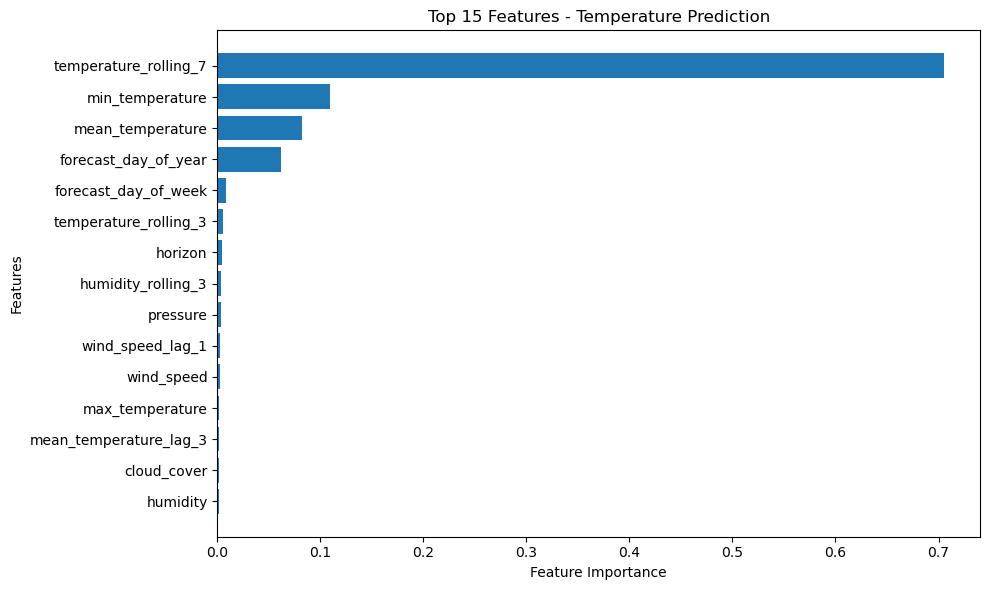

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the trained temperature model
temperature_model = joblib.load(
    PROJECT_DIR / "models" / "mean_temperature_random_forest.pkl"
)

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": multi_feature_columns,
    "Importance": temperature_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15).round(4))

# Visualize top 15 features
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df.head(15)["Feature"][::-1],
    importance_df.head(15)["Importance"][::-1]
)

plt.title("Top 15 Features - Temperature Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import pandas as pd

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Prepare temperature data
X_train_temp = rain_train[multi_feature_columns]
X_test_temp = rain_test[multi_feature_columns]

y_train_temp = rain_train["mean_temperature_target"]
y_test_temp = rain_test["mean_temperature_target"]

# Define models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    )
}

# Train and evaluate models
comparison_results = []

for name, model in models.items():

    model.fit(X_train_temp, y_train_temp)

    predictions = model.predict(X_test_temp)

    comparison_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_temp, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_temp, predictions)
        ),
        "R2 Score": r2_score(
            y_test_temp, predictions
        )
    })

# Display results
comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(comparison_df.round(4))

NameError: name 'rain_train' is not defined

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

# Set project directory
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

# Load processed weather data
data_path = PROJECT_DIR / "data" / "processed" / "weather_processed.csv"

weather_ml = pd.read_csv(data_path)

weather_ml["date"] = pd.to_datetime(weather_ml["date"])

weather_ml = weather_ml.sort_values("date").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", weather_ml.shape)

display(weather_ml.head())

Dataset loaded successfully!
Dataset shape: (1819, 30)


,date,max_temperature,min_temperature,mean_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover,year,...,humidity_lag_3,rainfall_lag_1,rainfall_lag_2,rainfall_lag_3,wind_speed_lag_1,wind_speed_lag_2,wind_speed_lag_3,temperature_rolling_3,temperature_rolling_7,humidity_rolling_3
0,2021-11-26,15.2,5.4,9.8,71,0.0,20.5,1014.2,2,2021,...,62.0,0.0,0.0,0.5,21.7,21.9,34.8,10.233333,11.285714,63.333333
1,2021-11-27,12.4,4.7,7.9,56,0.0,33.5,1021.4,6,2021,...,65.0,0.0,0.0,0.0,20.5,21.7,21.9,9.600000,11.114286,66.333333
2,2021-11-28,13.1,3.3,7.2,60,0.0,32.1,1030.0,7,2021,...,63.0,0.0,0.0,0.0,33.5,20.5,21.7,9.233333,10.557143,63.333333
3,2021-11-29,11.2,0.8,5.6,76,0.0,13.1,1029.5,48,2021,...,71.0,0.0,0.0,0.0,32.1,33.5,20.5,8.300000,9.957143,62.333333
4,2021-11-30,16.6,1.2,9.3,78,1.5,28.8,1021.5,47,2021,...,56.0,0.0,0.0,0.0,13.1,32.1,33.5,6.900000,8.742857,64.000000


In [3]:
# Define base features
BASE_FEATURES = [
    "mean_temperature",
    "max_temperature",
    "min_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure",
    "cloud_cover",
    "mean_temperature_lag_1",
    "mean_temperature_lag_2",
    "mean_temperature_lag_3",
    "humidity_lag_1",
    "rainfall_lag_1",
    "wind_speed_lag_1",
    "temperature_rolling_3",
    "temperature_rolling_7",
    "humidity_rolling_3"
]

# Define model features
multi_feature_columns = BASE_FEATURES + [
    "horizon",
    "forecast_month",
    "forecast_day_of_year",
    "forecast_day_of_week"
]

# Create seven-day forecasting records
records = []

for i in range(len(weather_ml) - 7):

    current = weather_ml.iloc[i]

    for horizon in range(1, 8):

        future = weather_ml.iloc[i + horizon]

        row = {
            feature: current[feature]
            for feature in BASE_FEATURES
        }

        row["horizon"] = horizon
        row["forecast_month"] = future["month"]
        row["forecast_day_of_year"] = future["day_of_year"]
        row["forecast_day_of_week"] = future["day_of_week"]

        row["origin_date"] = current["date"]
        row["target_date"] = future["date"]

        for target in [
            "mean_temperature",
            "humidity",
            "rainfall",
            "wind_speed"
        ]:
            row[target + "_target"] = future[target]

        records.append(row)

multi_forecast_df = pd.DataFrame(records)

print("Multi-day dataset created!")
print("Dataset shape:", multi_forecast_df.shape)

display(multi_forecast_df.head())

Multi-day dataset created!
Dataset shape: (12684, 27)


,mean_temperature,max_temperature,min_temperature,humidity,rainfall,wind_speed,pressure,cloud_cover,mean_temperature_lag_1,mean_temperature_lag_2,...,horizon,forecast_month,forecast_day_of_year,forecast_day_of_week,origin_date,target_date,mean_temperature_target,humidity_target,rainfall_target,wind_speed_target
0,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,1,11,331,5,2021-11-26,2021-11-27,7.9,56,0.0,33.5
1,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,2,11,332,6,2021-11-26,2021-11-28,7.2,60,0.0,32.1
2,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,3,11,333,0,2021-11-26,2021-11-29,5.6,76,0.0,13.1
3,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,4,11,334,1,2021-11-26,2021-11-30,9.3,78,1.5,28.8
4,9.8,15.2,5.4,71,0.0,20.5,1014.2,2,10.0,9.0,...,5,12,335,2,2021-11-26,2021-12-01,14.6,74,42.4,61.0


In [4]:
# Convert date columns
multi_forecast_df["origin_date"] = pd.to_datetime(
    multi_forecast_df["origin_date"]
)

multi_forecast_df["target_date"] = pd.to_datetime(
    multi_forecast_df["target_date"]
)

# Get unique forecast origin dates
unique_dates = np.sort(
    multi_forecast_df["origin_date"].unique()
)

# Calculate 80:20 split
split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

# Create training and testing datasets
rain_train = multi_forecast_df[
    multi_forecast_df["target_date"] < split_date
].copy()

rain_test = multi_forecast_df[
    multi_forecast_df["origin_date"] >= split_date
].copy()

print("Training and testing datasets created!")

print("Split date:", split_date)
print("Training shape:", rain_train.shape)
print("Testing shape:", rain_test.shape)

print(
    "Training date range:",
    rain_train["origin_date"].min(),
    "to",
    rain_train["origin_date"].max()
)

print(
    "Testing date range:",
    rain_test["origin_date"].min(),
    "to",
    rain_test["origin_date"].max()
)

Training and testing datasets created!
Split date: 2025-11-14T00:00:00.000000000
Training shape: (10115, 27)
Testing shape: (2541, 27)
Training date range: 2021-11-26 00:00:00 to 2025-11-12 00:00:00
Testing date range: 2025-11-14 00:00:00 to 2026-11-11 00:00:00


In [5]:
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Prepare temperature data
X_train_temp = rain_train[multi_feature_columns]
X_test_temp = rain_test[multi_feature_columns]

y_train_temp = rain_train["mean_temperature_target"]
y_test_temp = rain_test["mean_temperature_target"]

# Define models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    )
}

# Train and evaluate
comparison_results = []

for name, model in models.items():

    model.fit(X_train_temp, y_train_temp)

    predictions = model.predict(X_test_temp)

    comparison_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_temp, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_temp, predictions)
        ),
        "R2 Score": r2_score(
            y_test_temp, predictions
        )
    })

# Display results
comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        by="R2 Score",
        ascending=False
    ).round(4)
)

,Model,MAE,RMSE,R2 Score
1,Extra Trees,2.1988,2.7667,0.8802
2,Hist Gradient Boosting,2.2548,2.8257,0.8751
0,Random Forest,2.3712,2.9855,0.8605


In [6]:
import joblib

# Select the best model
best_temperature_model = models["Extra Trees"]

# Save model
model_path = PROJECT_DIR / "models" / "best_temperature_model.pkl"

joblib.dump(best_temperature_model, model_path)

print("Best temperature model saved successfully!")
print("Model:", model_path)
print("Algorithm: Extra Trees Regressor")

Best temperature model saved successfully!
Model: C:\Users\LOKI\Weather Prediction by Area\models\best_temperature_model.pkl
Algorithm: Extra Trees Regressor


In [7]:
import joblib

# Load the saved best temperature model
best_temperature_model = joblib.load(
    PROJECT_DIR / "models" / "best_temperature_model.pkl"
)

print("Extra Trees model loaded successfully!")

Extra Trees model loaded successfully!


In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

horizon_results = []

for horizon in range(1, 8):

    subset = rain_test[
        rain_test["horizon"] == horizon
    ]

    X_horizon = subset[multi_feature_columns]
    y_actual = subset["mean_temperature_target"]

    y_predicted = best_temperature_model.predict(
        X_horizon
    )

    horizon_results.append({
        "Horizon": f"Day {horizon}",
        "MAE": mean_absolute_error(
            y_actual, y_predicted
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_actual, y_predicted)
        ),
        "R2 Score": r2_score(
            y_actual, y_predicted
        )
    })

extra_trees_horizon_df = pd.DataFrame(horizon_results)

display(extra_trees_horizon_df.round(4))

# Save evaluation
extra_trees_horizon_df.to_csv(
    PROJECT_DIR / "data" / "processed" /
    "extra_trees_horizon_evaluation.csv",
    index=False
)

print("Horizon evaluation saved successfully!")

,Horizon,MAE,RMSE,R2 Score
0,Day 1,1.7344,2.1807,0.9257
1,Day 2,2.0772,2.5845,0.8956
2,Day 3,2.2425,2.7990,0.8775
3,Day 4,2.3204,2.9039,0.8683
4,Day 5,2.3301,2.9153,0.8671
5,Day 6,2.3158,2.9320,0.8653
6,Day 7,2.3712,2.9636,0.8621


Horizon evaluation saved successfully!


In [10]:
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load original Random Forest model
rf_model = joblib.load(
    PROJECT_DIR / "models" /
    "mean_temperature_random_forest.pkl"
)

rf_results = []

# Evaluate each forecast day
for horizon in range(1, 8):

    subset = rain_test[
        rain_test["horizon"] == horizon
    ]

    X = subset[multi_feature_columns]
    y_actual = subset["mean_temperature_target"]

    y_pred = rf_model.predict(X)

    rf_results.append({
        "Horizon": f"Day {horizon}",
        "MAE": mean_absolute_error(y_actual, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_actual, y_pred)),
        "R2 Score": r2_score(y_actual, y_pred)
    })

rf_horizon_df = pd.DataFrame(rf_results)

display(rf_horizon_df.round(4))

print("Random Forest evaluation recreated!")

,Horizon,MAE,RMSE,R2 Score
0,Day 1,2.0107,2.5011,0.9022
1,Day 2,2.1575,2.7483,0.8820
2,Day 3,2.3584,2.9680,0.8623
3,Day 4,2.5071,3.0966,0.8502
4,Day 5,2.5261,3.1713,0.8427
5,Day 6,2.5038,3.1706,0.8425
6,Day 7,2.5329,3.1851,0.8407


Random Forest evaluation recreated!


In [11]:
comparison_horizon = pd.DataFrame({
    "Horizon": rf_horizon_df["Horizon"],
    "RF_MAE": rf_horizon_df["MAE"],
    "ET_MAE": extra_trees_horizon_df["MAE"],
    "RF_R2": rf_horizon_df["R2 Score"],
    "ET_R2": extra_trees_horizon_df["R2 Score"]
})

comparison_horizon["MAE Improvement"] = (
    comparison_horizon["RF_MAE"] -
    comparison_horizon["ET_MAE"]
)

comparison_horizon["R2 Improvement"] = (
    comparison_horizon["ET_R2"] -
    comparison_horizon["RF_R2"]
)

display(comparison_horizon.round(4))

,Horizon,RF_MAE,ET_MAE,RF_R2,ET_R2,MAE Improvement,R2 Improvement
0,Day 1,2.0107,1.7344,0.9022,0.9257,0.2764,0.0234
1,Day 2,2.1575,2.0772,0.8820,0.8956,0.0804,0.0136
2,Day 3,2.3584,2.2425,0.8623,0.8775,0.1159,0.0152
3,Day 4,2.5071,2.3204,0.8502,0.8683,0.1867,0.0181
4,Day 5,2.5261,2.3301,0.8427,0.8671,0.1960,0.0244
5,Day 6,2.5038,2.3158,0.8425,0.8653,0.1880,0.0228
6,Day 7,2.5329,2.3712,0.8407,0.8621,0.1618,0.0214


In [12]:
import joblib
from pathlib import Path

# Save the best temperature model
model_path = PROJECT_DIR / "models" / "best_temperature_model.pkl"

joblib.dump(
    best_temperature_model,
    model_path
)

# Save the feature columns
feature_path = PROJECT_DIR / "models" / "temperature_feature_columns.pkl"

joblib.dump(
    multi_feature_columns,
    feature_path
)

print("Temperature model saved successfully!")
print("Algorithm: Extra Trees Regressor")
print("Model path:", model_path)
print("Feature columns saved:", feature_path)

Temperature model saved successfully!
Algorithm: Extra Trees Regressor
Model path: C:\Users\LOKI\Weather Prediction by Area\models\best_temperature_model.pkl
Feature columns saved: C:\Users\LOKI\Weather Prediction by Area\models\temperature_feature_columns.pkl


In [13]:
import joblib

loaded_model = joblib.load(
    PROJECT_DIR / "models" / "best_temperature_model.pkl"
)

loaded_features = joblib.load(
    PROJECT_DIR / "models" / "temperature_feature_columns.pkl"
)

print("Model verification successful!")
print("Model type:", type(loaded_model).__name__)
print("Number of features:", len(loaded_features))

Model verification successful!
Model type: ExtraTreesRegressor
Number of features: 21
